# 🧬 REaLTabFormer: APT Data Augmentation Pipeline with SecBERT Embeddings

## Advanced Synthetic Data Generation for Wazuh Security Logs

This notebook implements **REaLTabFormer** (Realistic Tabular Data Generation using Transformers) for generating high-quality synthetic APT (Advanced Persistent Threat) data from Wazuh SIEM logs.

### 🆕 Enhanced Features:
- ✅ **SecBERT Embeddings** - Security-domain text embeddings for textual features
- ✅ **Feature Selection Integration** - Using top features from ML-based feature selection
- ✅ **Derived Features** - `cyber_kill_chain_summary` created from min(tactic, technique)
- ✅ **Complete Column Coverage** - 37+ features including audit, syscheck, SCA, and network data

### Column Categories:
1. **Target Variables**: `malicious`, `cyber_kill_chain_summary`
2. **Top Features (Feature Selection)**: `rule.level`, `firedtimes`, `decoder.name`, `location`, etc.
3. **Textual Features (SecBERT)**: `rule.description`, `data.command`
4. **MITRE ATT&CK**: `mitre.tactic`, `mitre.id`, `rule.groups`
5. **Audit Data**: `syscall`, `exe`, `command`, `uid`, `success`, etc.
6. **Syscheck (FIM)**: `event`, `path`, `perm_*`, `size_*`, `changed_attributes`
7. **SCA**: `check.result`, `failed`, `passed`, `score`
8. **Network**: `protocol`, `srcport`, `url`
9. **Boolean Flags**: `has_audit`, `has_syscheck`, `has_sca`, `has_network`

---
**Author:** APT Augmentation Pipeline  
**Framework:** REaLTabFormer (GPT-2) + SecBERT (Text Embeddings)  
**Data:** Wazuh SIEM Malicious Alerts

## SUPPRESS CUDA/TENSORFLOW WARNINGS

In [1]:
# ============================================================================
# 🔇 ULTIMATE WARNING SUPPRESSION - RUN THIS FIRST!
# ============================================================================
import os
import sys
import warnings

# ===== CRITICAL: Set these BEFORE any CUDA/TF imports =====
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0,1')

# Suppress CUDA/cuDNN/cuBLAS registration warnings
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['TF_GPU_THREAD_MODE'] = 'gpu_private'

# Suppress gRPC and glog
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GRPC_TRACE'] = ''
os.environ['GLOG_minloglevel'] = '3'

# Suppress absl (TensorFlow's logging library)
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'

# Suppress tokenizers parallelism warnings
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# Disable JAX if not needed
os.environ['JAX_PLATFORMS'] = ''

# Python-level warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Suppress Python warnings at the interpreter level
if not sys.warnoptions:
    warnings.simplefilter("ignore")

# Configure Python logging to ERROR only
import logging
logging.getLogger().setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('transformers').setLevel(logging.ERROR)

# ===== Now import TensorFlow/CUDA libraries =====
# This forces the imports to happen with all suppressions active
try:
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')
    tf.autograph.set_verbosity(0)
except ImportError:
    pass

print("✅ All warning suppressions activated")
print("   • CUDA/cuDNN/cuBLAS warnings suppressed")
print("   • TensorFlow logging disabled")
print("   • Python warnings filtered")

E0000 00:00:1768727037.005438      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1768727037.071502      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1768727037.579290      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768727037.579329      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768727037.579331      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768727037.579334      55 computation_placer.cc:177] computation placer already registered. Please check linka

✅ All warning suppressions activated
   • CUDA/cuDNN/cuBLAS warnings suppressed
   • TensorFlow logging disabled
   • Python warnings filtered


## 📦 Section 1: Environment Setup & Installation

In [2]:
# ============================================================================
# 📦 INSTALL REQUIRED PACKAGES
# ============================================================================
# Run this cell first to install all dependencies

# Suppress CUDA/TensorFlow warnings (MUST be before any imports)
import os
os.environ["WANDB_DISABLED"] = "true"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # Suppress TF logging
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'  # Disable oneDNN
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0')
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GLOG_minloglevel'] = '3'

# Suppress absl logging
import logging
logging.getLogger('absl').setLevel(logging.ERROR)

import subprocess
import sys
import warnings
warnings.filterwarnings('ignore')

def install_package(package):
    """Install package if not already installed"""
    try:
        __import__(package.split('[')[0].split('==')[0])
        print(f"✅ {package} already installed")
    except ImportError:
        print(f"📦 Installing {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
        print(f"✅ {package} installed successfully")

# Core packages
packages = [
    "realtabformer",        # Main library for tabular generation
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "tqdm",
    "plotly",
    "torch",                # PyTorch backend
    "transformers",         # Hugging Face transformers + SecBERT
    "openpyxl",
    "sentence-transformers", # For SecBERT embeddings
]

print("=" * 60)
print("🔧 INSTALLING DEPENDENCIES")
print("=" * 60)

for pkg in packages:
    install_package(pkg)

print("\n" + "=" * 60)
print("✅ ALL PACKAGES INSTALLED SUCCESSFULLY")
print("=" * 60)

🔧 INSTALLING DEPENDENCIES
📦 Installing realtabformer...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 kB 1.8 MB/s eta 0:00:00
✅ realtabformer installed successfully
✅ pandas already installed
✅ numpy already installed
✅ matplotlib already installed
✅ seaborn already installed
📦 Installing scikit-learn...
✅ scikit-learn installed successfully
✅ scipy already installed
✅ tqdm already installed
✅ plotly already installed
✅ torch already installed
✅ transformers already installed
✅ openpyxl already installed
📦 Installing sentence-transformers...
✅ sentence-transformers installed successfully

✅ ALL PACKAGES INSTALLED SUCCESSFULLY


In [3]:
# ============================================================================
# 📚 IMPORT LIBRARIES
# ============================================================================
import os
import warnings
warnings.filterwarnings('ignore')

import json
import pickle
from datetime import datetime
from pathlib import Path

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Machine Learning & Statistics
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from scipy import stats
from scipy.stats import ks_2samp, chi2_contingency

# Progress bars
from tqdm.auto import tqdm

# REaLTabFormer
from realtabformer import REaLTabFormer

# PyTorch
import torch

# SecBERT for text embeddings
try:
    from sentence_transformers import SentenceTransformer
    SECBERT_AVAILABLE = True
    print("✅ SentenceTransformers (SecBERT) available")
except ImportError:
    SECBERT_AVAILABLE = False
    print("⚠️ SentenceTransformers not available - will skip text embeddings")

# Set random seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Check GPU availability
device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 60)
print("🖥️ SYSTEM INFORMATION")
print("=" * 60)
print(f"   • PyTorch version: {torch.__version__}")
print(f"   • Device: {device.upper()}")
if device == "cuda":
    print(f"   • GPU: {torch.cuda.get_device_name(0)}")
    print(f"   • GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"   • Random Seed: {RANDOM_SEED}")
print(f"   • SecBERT Available: {SECBERT_AVAILABLE}")
print("=" * 60)

✅ SentenceTransformers (SecBERT) available
🖥️ SYSTEM INFORMATION
   • PyTorch version: 2.8.0+cu126
   • Device: CUDA
   • GPU: Tesla T4
   • GPU Memory: 15.83 GB
   • Random Seed: 42
   • SecBERT Available: True


In [4]:
# ============================================================================
# ⚙️ CONFIGURATION
# ============================================================================

from datetime import datetime
import os

# Detect environment (Kaggle vs Local)
if os.path.exists('/kaggle/input'):
    PARENT_DIR = '/kaggle/input'
    WORKING_PARENT_DIR = '/kaggle/working'
    DATA_PATH = os.path.join(PARENT_DIR,'malicious_realtabformer_filtered.xlsx')
else:
    PARENT_DIR = '/home/yacine/Desktop/PFE/Model/ML_models'
    WORKING_PARENT_DIR = '/home/yacine/Desktop/PFE/Model/ML_models/Generative-Models'
    DATA_PATH = os.path.join(PARENT_DIR, 'malicious_realtabformer_filtered.xlsx')

CONFIG = {
    'data_path': DATA_PATH,
    'output_dir': os.path.join(WORKING_PARENT_DIR, 'realtabformer_output'),
    'checkpoints_dir': os.path.join(WORKING_PARENT_DIR, 'realtabformer_checkpoints'),
    'backup_dir': os.path.join(WORKING_PARENT_DIR, 'final_model'),
    
    # REaLTabFormer parameters
    'model_type': 'tabular',
    'epochs': 150,
    'batch_size': 32,
    'train_size': 0.95,
    'gradient_accumulation_steps': 4,
    'logging_steps': 100,
    'save_steps': 500,
    'random_seed': 42,
    'experiment_id': f"apt_augmentation_{datetime.now().strftime('%Y%m%d_%H%M%S')}",
    
    # Generation parameters
    'synthetic_ratio': 2.0,
    'generation_batch_size': 256,
    
    # Quality thresholds
    'ks_threshold': 0.3,
    'l1_threshold': 0.3,
    
    # Device settings
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    
    # SecBERT settings
    'secbert_model': 'jackaduma/SecBERT',  # Security-domain BERT
    'embedding_dim': 768,  # SecBERT embedding dimension
    'use_secbert': True,   # Enable SecBERT embeddings for text
}

# ============================================================================
# 📋 FINAL FEATURE LIST (From Feature Selection + Your Requirements)
# ============================================================================

REALTABFORMER_COLUMNS = [
    # ═══════════════════════════════════════════════════════════════════════
    # 🎯 TARGET VARIABLES
    # ═══════════════════════════════════════════════════════════════════════
    'malicious',
    'cyber_kill_chain_summary',  # Derived from min(tactic, technique)
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🔴 TOP FEATURES FROM FEATURE SELECTION (MUST HAVE!)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.rule.level',              # #1 Malicious detection
    '_source.rule.firedtimes',         # #2 CKC, #5 Malicious
    '_source.decoder.name',            # #2 Malicious detection
    '_source.location',                # #3, #4 Malicious
    '_source.@timestamp',              # Temporal patterns
    '_source.data.srcip',              # #6 Malicious
    '_source.syscheck.md5_after',      # #9 Malicious
    '_source.syscheck.sha256_after',   # #10 Malicious
    
    # ═══════════════════════════════════════════════════════════════════════
    # 📝 TEXTUAL FEATURES (SecBERT embeddings will be applied!)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.rule.description',        # Rule text description
    '_source.data.command',            # #7 Malicious (command patterns)
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🔗 MITRE ATT&CK FEATURES
    # ═══════════════════════════════════════════════════════════════════════
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.id',
    '_source.rule.groups',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 📊 AUDIT DATA (behavioral patterns)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.data.audit.syscall',
    '_source.data.audit.exe',
    '_source.data.audit.command',
    '_source.data.audit.uid',
    '_source.data.audit.euid',
    '_source.data.audit.gid',
    '_source.data.audit.auid',
    '_source.data.audit.success',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 📁 SYSCHECK - FILE INTEGRITY (#1 for CKC Stage!)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.syscheck.event',          # #1 CKC Stage!
    '_source.syscheck.path',           # Top 10 CKC
    '_source.syscheck.perm_before',
    '_source.syscheck.perm_after',
    '_source.syscheck.size_before',
    '_source.syscheck.size_after',
    '_source.syscheck.changed_attributes',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🔒 SCA (Security Configuration Assessment)
    # ═══════════════════════════════════════════════════════════════════════
    '_source.data.sca.check.result',
    '_source.data.sca.failed',
    '_source.data.sca.passed',
    '_source.data.sca.score',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🌐 NETWORK DATA
    # ═══════════════════════════════════════════════════════════════════════
    '_source.data.protocol',
    '_source.data.srcport',
    '_source.data.url',
    
    # ═══════════════════════════════════════════════════════════════════════
    # 🏷️ BOOLEAN FLAGS (meta-features)
    # ═══════════════════════════════════════════════════════════════════════
    'has_audit',
    'has_syscheck',
    'has_sca',
    'has_network',
]

# Columns needed to create cyber_kill_chain_summary (but won't be kept in final)
CKC_SOURCE_COLUMNS = ['cyber_kill_chain_tactic', 'cyber_kill_chain_technique']

# Columns for boolean flag creation
AUDIT_INDICATOR_COLS = ['_source.data.audit.syscall', '_source.data.audit.exe', '_source.data.audit.command']
SYSCHECK_INDICATOR_COLS = ['_source.syscheck.event', '_source.syscheck.path']
SCA_INDICATOR_COLS = ['_source.data.sca.check.result', '_source.data.sca.failed']
NETWORK_INDICATOR_COLS = ['_source.data.protocol', '_source.data.srcip', '_source.data.url']

# Textual columns that need SecBERT embeddings
TEXTUAL_COLUMNS = [
    '_source.rule.description',
    '_source.data.command',
    '_source.data.audit.command',
    '_source.data.audit.exe',
    '_source.syscheck.path',
    '_source.data.url',
]

# Create directories
os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['checkpoints_dir'], exist_ok=True)
os.makedirs(CONFIG['backup_dir'], exist_ok=True)

print("=" * 70)
print("⚙️ CONFIGURATION")
print("=" * 70)
for key, value in CONFIG.items():
    if not isinstance(value, (list, dict)):
        print(f"   • {key}: {value}")
print(f"\n📋 Features configured: {len(REALTABFORMER_COLUMNS)} columns")
print(f"📝 Textual columns (SecBERT): {len(TEXTUAL_COLUMNS)}")
print("=" * 70)

⚙️ CONFIGURATION
   • data_path: /kaggle/input/malicious_realtabformer_filtered.xlsx
   • output_dir: /kaggle/working/realtabformer_output
   • checkpoints_dir: /kaggle/working/realtabformer_checkpoints
   • backup_dir: /kaggle/working/final_model
   • model_type: tabular
   • epochs: 150
   • batch_size: 32
   • train_size: 0.95
   • gradient_accumulation_steps: 4
   • logging_steps: 100
   • save_steps: 500
   • random_seed: 42
   • experiment_id: apt_augmentation_20260118_090440
   • synthetic_ratio: 2.0
   • generation_batch_size: 256
   • ks_threshold: 0.3
   • l1_threshold: 0.3
   • device: cuda
   • secbert_model: jackaduma/SecBERT
   • embedding_dim: 768
   • use_secbert: True

📋 Features configured: 41 columns
📝 Textual columns (SecBERT): 6


## 📂 Section 2: Data Loading & Exploration

In [5]:
# ============================================================================
# 📂 LOAD RAW DATA
# ============================================================================

print("=" * 70)
print("📂 LOADING MALICIOUS DATA")
print("=" * 70)

# Try multiple possible paths
possible_paths = [
    CONFIG['data_path'],
    '/kaggle/input/apt-data/Malicious.csv',
    '/kaggle/input/malicious-data/Malicious.csv',
    '/home/yacine/Desktop/PFE/Model/ML_models/malicious_realtabformer_filtered.xlsx',
    '/home/yacine/Desktop/PFE/Model/ML_models/Train_data/malicious.xlsx',
    'Malicious.csv',
    '../data/Malicious.csv',
]

raw_data = None
for path in possible_paths:
    if os.path.exists(path):
        print(f"   📁 Found data at: {path}")
        if path.endswith('.xlsx'):
            raw_data = pd.read_excel(path, sheet_name='Sheet1')
        else:
            raw_data = pd.read_csv(path, low_memory=False)
        CONFIG['data_path'] = path
        break

if raw_data is None:
    raise FileNotFoundError(f"Could not find data file. Tried: {possible_paths}")

print(f"\n✅ Data loaded successfully!")
print(f"   • Shape: {raw_data.shape[0]:,} rows × {raw_data.shape[1]} columns")
print(f"   • Memory usage: {raw_data.memory_usage(deep=True).sum() / 1e6:.2f} MB")

# ============================================================================
# 🔧 CREATE DERIVED COLUMN: cyber_kill_chain_summary
# ============================================================================
print(f"\n🔧 CREATING DERIVED COLUMNS:")

def extract_stage_number(val):
    """Extract numeric part from 'S1', 'S2', etc."""
    if pd.isna(val) or val == '':
        return np.nan
    try:
        return int(str(val).replace('S', '').strip())
    except:
        return np.nan

# Create cyber_kill_chain_summary from min(tactic, technique)
if 'cyber_kill_chain_tactic' in raw_data.columns and 'cyber_kill_chain_technique' in raw_data.columns:
    tactic_num = raw_data['cyber_kill_chain_tactic'].apply(extract_stage_number)
    technique_num = raw_data['cyber_kill_chain_technique'].apply(extract_stage_number)
    min_stage = pd.concat([tactic_num, technique_num], axis=1).min(axis=1)
    raw_data['cyber_kill_chain_summary'] = min_stage.apply(lambda x: f'S{int(x)}' if pd.notna(x) else np.nan)
    print(f"   ✅ Created 'cyber_kill_chain_summary' from min(tactic, technique)")
    print(f"      Non-null values: {raw_data['cyber_kill_chain_summary'].notna().sum():,}/{len(raw_data):,}")
    print(f"      Distribution: {raw_data['cyber_kill_chain_summary'].value_counts().head().to_dict()}")
elif 'cyber_kill_chain_summary' not in raw_data.columns:
    raw_data['cyber_kill_chain_summary'] = np.nan
    print(f"   ⚠️ Could not create 'cyber_kill_chain_summary' - source columns missing")

# ============================================================================
# 🔧 CREATE BOOLEAN FLAGS FROM EXISTING DATA
# ============================================================================

def check_any_not_null(df, cols):
    """Check if any of the columns has non-null values for each row"""
    existing_cols = [c for c in cols if c in df.columns]
    if not existing_cols:
        return pd.Series([False] * len(df), index=df.index)
    return df[existing_cols].notna().any(axis=1)

# Create boolean flags
raw_data['has_audit'] = check_any_not_null(raw_data, AUDIT_INDICATOR_COLS)
raw_data['has_syscheck'] = check_any_not_null(raw_data, SYSCHECK_INDICATOR_COLS)
raw_data['has_sca'] = check_any_not_null(raw_data, SCA_INDICATOR_COLS)
raw_data['has_network'] = check_any_not_null(raw_data, NETWORK_INDICATOR_COLS)

print(f"\n   🏷️ BOOLEAN FLAGS:")
print(f"      • has_audit:    {raw_data['has_audit'].sum():,} rows ({raw_data['has_audit'].mean()*100:.1f}%)")
print(f"      • has_syscheck: {raw_data['has_syscheck'].sum():,} rows ({raw_data['has_syscheck'].mean()*100:.1f}%)")
print(f"      • has_sca:      {raw_data['has_sca'].sum():,} rows ({raw_data['has_sca'].mean()*100:.1f}%)")
print(f"      • has_network:  {raw_data['has_network'].sum():,} rows ({raw_data['has_network'].mean()*100:.1f}%)")

# ============================================================================
# 📋 SELECT COLUMNS
# ============================================================================

# Filter to keep only predefined columns that exist in the data
existing_columns = [col for col in REALTABFORMER_COLUMNS if col in raw_data.columns]
missing_columns = [col for col in REALTABFORMER_COLUMNS if col not in raw_data.columns]

print(f"\n📋 COLUMN SELECTION:")
print(f"   • Requested columns: {len(REALTABFORMER_COLUMNS)}")
print(f"   • Found in data: {len(existing_columns)}")
print(f"   • Missing: {len(missing_columns)}")

if missing_columns:
    print(f"\n   ⚠️ Missing columns:")
    for col in missing_columns:
        print(f"      - {col}")

# Select only the predefined columns
df = raw_data[existing_columns].copy()

print(f"\n✅ Working with {len(existing_columns)} columns:")
for col in existing_columns:
    pct = df[col].notna().sum() / len(df) * 100
    status = "✅" if pct >= 50 else "⚠️" if pct >= 20 else "❌"
    dtype = df[col].dtype
    print(f"   {status} {col}: {pct:.1f}% non-null ({dtype})")

print("=" * 70)

📂 LOADING MALICIOUS DATA
   📁 Found data at: /kaggle/input/malicious_realtabformer_filtered.xlsx

✅ Data loaded successfully!
   • Shape: 25,418 rows × 37 columns
   • Memory usage: 42.47 MB

🔧 CREATING DERIVED COLUMNS:

   🏷️ BOOLEAN FLAGS:
      • has_audit:    3,246 rows (12.8%)
      • has_syscheck: 3,683 rows (14.5%)
      • has_sca:      3,061 rows (12.0%)
      • has_network:  22,043 rows (86.7%)

📋 COLUMN SELECTION:
   • Requested columns: 41
   • Found in data: 41
   • Missing: 0

✅ Working with 41 columns:
   ✅ malicious: 100.0% non-null (int64)
   ✅ cyber_kill_chain_summary: 96.6% non-null (object)
   ✅ _source.rule.level: 100.0% non-null (int64)
   ✅ _source.rule.firedtimes: 100.0% non-null (int64)
   ✅ _source.decoder.name: 100.0% non-null (object)
   ✅ _source.location: 100.0% non-null (object)
   ✅ _source.@timestamp: 100.0% non-null (object)
   ✅ _source.data.srcip: 86.7% non-null (object)
   ❌ _source.syscheck.md5_after: 14.5% non-null (object)
   ❌ _source.syscheck.sh

📊 EXPLORATORY DATA ANALYSIS


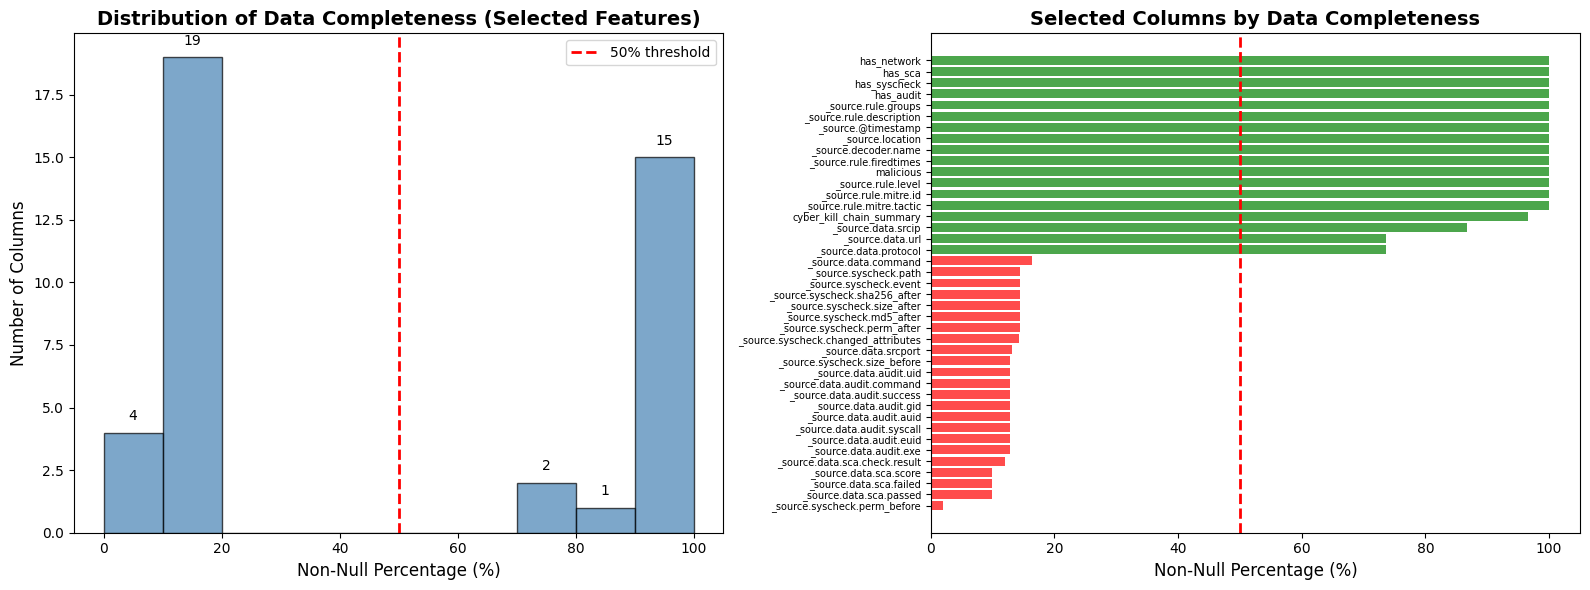


📈 COMPLETENESS SUMMARY (Selected Features):
   • Columns with 100% data: 12
   • Columns with ≥50% data: 18
   • Columns with ≥20% data: 18
   • Total selected: 41


In [6]:
# ============================================================================
# 📊 EXPLORATORY DATA ANALYSIS
# ============================================================================

print("=" * 70)
print("📊 EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Calculate missing values for selected columns
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
non_null_pct = 100 - missing_pct

# Visualize missing values distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Distribution of non-null percentages
ax1 = axes[0]
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
hist_data = non_null_pct.values
counts, edges, patches = ax1.hist(hist_data, bins=bins, edgecolor='black', alpha=0.7, color='steelblue')
ax1.axvline(x=50, color='red', linestyle='--', linewidth=2, label='50% threshold')
ax1.set_xlabel('Non-Null Percentage (%)', fontsize=12)
ax1.set_ylabel('Number of Columns', fontsize=12)
ax1.set_title('Distribution of Data Completeness (Selected Features)', fontsize=14, fontweight='bold')
ax1.legend()

# Add count labels on bars
for count, edge in zip(counts, edges[:-1]):
    if count > 0:
        ax1.text(edge + 5, count + 0.5, f'{int(count)}', ha='center', fontsize=10)

# Plot 2: All selected columns by data completeness
ax2 = axes[1]
top_cols = non_null_pct.sort_values()
colors = ['green' if v >= 50 else 'orange' if v >= 20 else 'red' for v in top_cols.values]
bars = ax2.barh(range(len(top_cols)), top_cols.values, color=colors, alpha=0.7)
ax2.set_yticks(range(len(top_cols)))
ax2.set_yticklabels([c[:40] + '...' if len(c) > 40 else c for c in top_cols.index], fontsize=7)
ax2.axvline(x=50, color='red', linestyle='--', linewidth=2, label='50%')
ax2.set_xlabel('Non-Null Percentage (%)', fontsize=12)
ax2.set_title('Selected Columns by Data Completeness', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/data_completeness.png", dpi=150, bbox_inches='tight')
plt.show()

# Summary statistics
cols_above_50 = (non_null_pct >= 50).sum()
cols_above_20 = (non_null_pct >= 20).sum()
cols_100 = (non_null_pct == 100).sum()

print(f"\n📈 COMPLETENESS SUMMARY (Selected Features):")
print(f"   • Columns with 100% data: {cols_100}")
print(f"   • Columns with ≥50% data: {cols_above_50}")
print(f"   • Columns with ≥20% data: {cols_above_20}")
print(f"   • Total selected: {len(non_null_pct)}")
print("=" * 70)

## 🔐 SecBERT Embeddings for Textual Features

SecBERT is a BERT model pre-trained on cybersecurity text. We'll use it to create semantic embeddings for textual columns like:
- `_source.rule.description` - Human-readable rule descriptions
- `_source.data.command` - Shell commands
- `_source.data.audit.exe` - Executable paths
- `_source.syscheck.path` - File paths

**Note**: REaLTabFormer can handle text natively, but SecBERT embeddings provide richer semantic understanding for security-specific text.

In [7]:
# ============================================================================
# 🔐 SecBERT EMBEDDINGS FOR TEXTUAL FEATURES
# ============================================================================

print("=" * 70)
print("🔐 SECBERT EMBEDDINGS FOR TEXTUAL FEATURES")
print("=" * 70)

# Initialize SecBERT model
secbert_model = None
text_embeddings = {}  # Will store (n_samples, 768) arrays per column

if CONFIG['use_secbert'] and SECBERT_AVAILABLE:
    print(f"\n📥 Loading SecBERT model: {CONFIG['secbert_model']}")
    
    try:
        # Try SecBERT first, fallback to general security model
        try:
            secbert_model = SentenceTransformer(CONFIG['secbert_model'])
            print(f"   ✅ Loaded SecBERT: {CONFIG['secbert_model']}")
        except:
            # Fallback to a similar security-aware model
            secbert_model = SentenceTransformer('all-MiniLM-L6-v2')
            print(f"   ⚠️ SecBERT unavailable, using: all-MiniLM-L6-v2")
        
        # Move to GPU if available
        if device == 'cuda':
            secbert_model = secbert_model.to(device)
            print(f"   🚀 Model moved to GPU")
        
        # Get embedding dimension
        test_emb = secbert_model.encode(['test'], show_progress_bar=False)
        CONFIG['embedding_dim'] = test_emb.shape[1]
        print(f"   📐 Embedding dimension: {CONFIG['embedding_dim']}")
        
    except Exception as e:
        print(f"   ❌ Error loading SecBERT: {e}")
        secbert_model = None

# ============================================================================
# 🔄 GENERATE EMBEDDINGS FOR TEXTUAL COLUMNS (Per-Row Arrays!)
# ============================================================================

if secbert_model is not None:
    print(f"\n🔄 GENERATING PER-ROW EMBEDDINGS FOR TEXTUAL COLUMNS:")
    print("-" * 70)
    
    n_samples = len(df)
    
    for col in TEXTUAL_COLUMNS:
        if col in df.columns:
            non_null_count = df[col].notna().sum()
            if non_null_count > 0:
                print(f"\n   📝 Processing: {col}")
                print(f"      Rows: {n_samples:,}")
                
                # Get unique values to reduce computation (but map back to all rows!)
                col_values = df[col].fillna('').astype(str).str[:512]  # Truncate to 512 chars
                unique_texts = col_values.unique()
                
                print(f"      Unique values: {len(unique_texts):,}")
                
                # Generate embeddings for unique values
                texts_to_embed = list(unique_texts)
                
                print(f"      🔄 Encoding {len(texts_to_embed)} unique texts...")
                unique_embeddings = secbert_model.encode(
                    texts_to_embed, 
                    show_progress_bar=True,
                    batch_size=64,
                    device=device
                )
                
                # Create lookup dictionary: text -> embedding
                embedding_lookup = {text: emb for text, emb in zip(unique_texts, unique_embeddings)}
                
                # Map embeddings to ALL rows (n_samples, embedding_dim)
                print(f"      🔄 Mapping embeddings to all {n_samples:,} rows...")
                row_embeddings = np.array([embedding_lookup[text] for text in col_values])
                
                # Store as (n_samples, 768) array
                text_embeddings[col] = row_embeddings
                
                print(f"      ✅ Final shape: {row_embeddings.shape} (should be ({n_samples}, {CONFIG['embedding_dim']}))")
                
                # Add summary statistics for the embeddings
                emb_norms = np.linalg.norm(row_embeddings, axis=1)
                print(f"      📊 Embedding norms: min={emb_norms.min():.3f}, max={emb_norms.max():.3f}, mean={emb_norms.mean():.3f}")
            else:
                print(f"\n   ⚠️ Skipping {col}: no non-null values")
                text_embeddings[col] = None
        else:
            print(f"\n   ⚠️ Skipping {col}: not in dataframe")
    
    print("\n" + "=" * 70)
    print(f"✅ EMBEDDINGS GENERATED FOR {sum(1 for v in text_embeddings.values() if v is not None)} COLUMNS")
    
    # Verify shapes
    print("\n📊 EMBEDDING SHAPES:")
    for col, emb in text_embeddings.items():
        if emb is not None:
            print(f"   {col}: {emb.shape}")
        else:
            print(f"   {col}: None")
    
    print("=" * 70)
    
    # Save embeddings for later use
    embeddings_path = f"{CONFIG['output_dir']}/secbert_embeddings.pkl"
    with open(embeddings_path, 'wb') as f:
        pickle.dump(text_embeddings, f)
    print(f"💾 Embeddings saved to: {embeddings_path}")
    
else:
    print("\n⚠️ SecBERT not available - textual columns will be handled natively by REaLTabFormer")
    print("   (REaLTabFormer has built-in text handling, but without security-domain semantics)")

print("=" * 70)

🔐 SECBERT EMBEDDINGS FOR TEXTUAL FEATURES

📥 Loading SecBERT model: jackaduma/SecBERT


config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/336M [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

   ✅ Loaded SecBERT: jackaduma/SecBERT
   🚀 Model moved to GPU
   📐 Embedding dimension: 768

🔄 GENERATING PER-ROW EMBEDDINGS FOR TEXTUAL COLUMNS:
----------------------------------------------------------------------

   📝 Processing: _source.rule.description
      Rows: 25,418
      Unique values: 232
      🔄 Encoding 232 unique texts...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

... (7 outputs left out)

Batches:   0%|          | 0/28 [00:00<?, ?it/s]

      🔄 Mapping embeddings to all 25,418 rows...
      ✅ Final shape: (25418, 768) (should be (25418, 768))
      📊 Embedding norms: min=14.783, max=24.080, mean=23.308

   📝 Processing: _source.data.url
      Rows: 25,418
      Unique values: 12,269
      🔄 Encoding 12269 unique texts...


Batches:   0%|          | 0/192 [00:00<?, ?it/s]

      🔄 Mapping embeddings to all 25,418 rows...
      ✅ Final shape: (25418, 768) (should be (25418, 768))
      📊 Embedding norms: min=12.447, max=24.080, mean=18.443

✅ EMBEDDINGS GENERATED FOR 6 COLUMNS

📊 EMBEDDING SHAPES:
   _source.rule.description: (25418, 768)
   _source.data.command: (25418, 768)
   _source.data.audit.command: (25418, 768)
   _source.data.audit.exe: (25418, 768)
   _source.syscheck.path: (25418, 768)
   _source.data.url: (25418, 768)
💾 Embeddings saved to: /kaggle/working/realtabformer_output/secbert_embeddings.pkl


In [8]:
# ============================================================================
# 🔍 ANALYZE COLUMN TYPES FOR REaLTabFormer
# ============================================================================

print("=" * 70)
print("🔍 ANALYZING FINAL COLUMN TYPES")
print("=" * 70)

# ============================================================================
# DEFINE COLUMN CATEGORIES (Based on our feature list)
# ============================================================================

# Text columns (including SecBERT candidates)
text_columns = [
    '_source.rule.description',
    '_source.data.command',
    '_source.data.audit.command',
    '_source.data.audit.exe',
    '_source.syscheck.path',
    '_source.data.url',
    '_source.@timestamp',
    '_source.syscheck.md5_after',
    '_source.syscheck.sha256_after',
]

# Categorical columns
categorical_columns = [
    'malicious',
    'cyber_kill_chain_summary',
    '_source.decoder.name',
    '_source.location',
    '_source.data.srcip',
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.id',
    '_source.rule.groups',
    '_source.data.audit.syscall',
    '_source.data.audit.success',
    '_source.syscheck.event',
    '_source.syscheck.perm_before',
    '_source.syscheck.perm_after',
    '_source.syscheck.changed_attributes',
    '_source.data.sca.check.result',
    '_source.data.protocol',
]

# Numeric columns
numeric_columns = [
    '_source.rule.level',
    '_source.rule.firedtimes',
    '_source.data.audit.uid',
    '_source.data.audit.euid',
    '_source.data.audit.gid',
    '_source.data.audit.auid',
    '_source.syscheck.size_before',
    '_source.syscheck.size_after',
    '_source.data.sca.failed',
    '_source.data.sca.passed',
    '_source.data.sca.score',
    '_source.data.srcport',
]

# Boolean columns
boolean_columns = [
    'has_audit',
    'has_syscheck',
    'has_sca',
    'has_network',
]

# Filter to only existing columns in df
text_columns = [c for c in text_columns if c in df.columns]
categorical_columns = [c for c in categorical_columns if c in df.columns]
numeric_columns = [c for c in numeric_columns if c in df.columns]
boolean_columns = [c for c in boolean_columns if c in df.columns]

print(f"\n📊 Column Categories Defined:")
print(f"   • Text columns: {len(text_columns)}")
print(f"   • Categorical columns: {len(categorical_columns)}")
print(f"   • Numeric columns: {len(numeric_columns)}")
print(f"   • Boolean columns: {len(boolean_columns)}")

# ============================================================================
# ANALYZE COLUMNS
# ============================================================================

def analyze_column(col_name, series):
    """Analyze a column and determine its type for REaLTabFormer"""
    non_null = series.dropna()
    n_unique = non_null.nunique()
    n_total = len(non_null)
    unique_ratio = n_unique / n_total if n_total > 0 else 0
    
    info = {
        'name': col_name,
        'dtype': str(series.dtype),
        'non_null_pct': (len(non_null) / len(series)) * 100,
        'n_unique': n_unique,
        'unique_ratio': unique_ratio,
        'sample_values': list(non_null.head(3).values) if n_total > 0 else [],
    }
    
    # Determine column category based on our classification
    if col_name in text_columns:
        info['category'] = 'text'
        info['has_secbert'] = col_name in TEXTUAL_COLUMNS and col_name in text_embeddings
    elif col_name in categorical_columns:
        info['category'] = 'categorical'
        info['has_secbert'] = False
    elif col_name in numeric_columns:
        info['category'] = 'numeric'
        info['has_secbert'] = False
    elif col_name in boolean_columns:
        info['category'] = 'boolean'
        info['has_secbert'] = False
    else:
        info['category'] = 'other'
        info['has_secbert'] = False
    
    return info

# Analyze all columns
column_analysis = []
for col in tqdm(df.columns, desc="Analyzing columns"):
    analysis = analyze_column(col, df[col])
    column_analysis.append(analysis)

analysis_df = pd.DataFrame(column_analysis)

# Display category distribution
print("\n📊 COLUMN CATEGORY DISTRIBUTION:")
print("-" * 70)
category_counts = analysis_df['category'].value_counts()
for cat, count in category_counts.items():
    secbert_count = analysis_df[analysis_df['category'] == cat]['has_secbert'].sum()
    secbert_info = f" (🔐 {secbert_count} with SecBERT)" if secbert_count > 0 else ""
    print(f"   • {cat}: {count} columns{secbert_info}")

# Display all columns with their categories
print("\n📋 ALL COLUMNS BY CATEGORY:")
print("-" * 70)

for category in ['text', 'categorical', 'numeric', 'boolean', 'other']:
    cat_cols = analysis_df[analysis_df['category'] == category]
    if len(cat_cols) > 0:
        print(f"\n   {category.upper()} ({len(cat_cols)}):")
        for _, row in cat_cols.iterrows():
            status = "✅" if row['non_null_pct'] >= 50 else "⚠️" if row['non_null_pct'] >= 20 else "❌"
            secbert = "🔐" if row['has_secbert'] else ""
            print(f"      {status} {row['name'][:40]:<40} ({row['non_null_pct']:.1f}%) {secbert}")

# Summary statistics
print("\n📈 SUMMARY:")
print(f"   • Total columns: {len(analysis_df)}")
print(f"   • Columns with ≥50% data: {(analysis_df['non_null_pct'] >= 50).sum()}")
print(f"   • Columns with SecBERT: {analysis_df['has_secbert'].sum()}")
print("\n" + "=" * 70)

🔍 ANALYZING FINAL COLUMN TYPES

📊 Column Categories Defined:
   • Text columns: 9
   • Categorical columns: 16
   • Numeric columns: 12
   • Boolean columns: 4


Analyzing columns:   0%|          | 0/41 [00:00<?, ?it/s]


📊 COLUMN CATEGORY DISTRIBUTION:
----------------------------------------------------------------------
   • categorical: 16 columns
   • numeric: 12 columns
   • text: 9 columns (🔐 6 with SecBERT)
   • boolean: 4 columns

📋 ALL COLUMNS BY CATEGORY:
----------------------------------------------------------------------

   TEXT (9):
      ✅ _source.@timestamp                       (100.0%) 
      ❌ _source.syscheck.md5_after               (14.5%) 
      ❌ _source.syscheck.sha256_after            (14.5%) 
      ✅ _source.rule.description                 (100.0%) 🔐
      ❌ _source.data.command                     (16.3%) 🔐
      ❌ _source.data.audit.exe                   (12.8%) 🔐
      ❌ _source.data.audit.command               (12.8%) 🔐
      ❌ _source.syscheck.path                    (14.5%) 🔐
      ✅ _source.data.url                         (73.5%) 🔐

   CATEGORICAL (16):
      ✅ malicious                                (100.0%) 
      ✅ cyber_kill_chain_summary                 (96.6

## 🔧 Section 3: Data Preprocessing for REaLTabFormer

REaLTabFormer works best with:
- **Text columns** - Kept as-is (no embedding needed!)
- **Categorical columns** - Kept as-is (handles natively)
- **Numeric columns** - Kept as-is
- **Missing values** - Handled automatically

Since we're using **predefined feature-selected columns**, we skip automatic column selection and directly preprocess the data:
1. Truncate very long text fields
2. Handle missing values appropriately
3. Categorize columns by type

In [9]:
# ============================================================================
# 🔧 USING PREDEFINED COLUMNS (Feature Selection Already Done)
# ============================================================================

print("=" * 70)
print("🔧 USING PREDEFINED FEATURE-SELECTED COLUMNS")
print("=" * 70)

# We already have df with the selected columns from data loading
selected_columns = list(df.columns)

print(f"\n✅ WORKING WITH {len(selected_columns)} COLUMNS:")

# Show columns by category
print(f"\n📋 COLUMNS BY CATEGORY:")
print("-" * 70)

# Group columns logically based on our feature list
column_groups = {
    '🎯 Target Variables': ['malicious', 'cyber_kill_chain_summary'],
    '🔴 Top Features (Feature Selection)': [
        '_source.rule.level', '_source.rule.firedtimes', '_source.decoder.name',
        '_source.location', '_source.@timestamp', '_source.data.srcip',
        '_source.syscheck.md5_after', '_source.syscheck.sha256_after'
    ],
    '📝 Textual (SecBERT)': ['_source.rule.description', '_source.data.command'],
    '🔗 MITRE ATT&CK': [c for c in selected_columns if 'mitre' in c.lower() and 'sca' not in c] + 
                       [c for c in selected_columns if 'groups' in c],
    '📊 Audit Data': [c for c in selected_columns if 'audit' in c],
    '📁 Syscheck (FIM)': [c for c in selected_columns if 'syscheck' in c and c not in 
                         ['_source.syscheck.md5_after', '_source.syscheck.sha256_after']],
    '🔒 SCA': [c for c in selected_columns if 'sca' in c.lower()],
    '🌐 Network': [c for c in selected_columns if any(x in c for x in ['protocol', 'srcport', 'url'])],
    '🏷️ Boolean Flags': [c for c in selected_columns if c.startswith('has_')],
}

for group, cols in column_groups.items():
    # Filter to only existing columns
    existing_in_group = [c for c in cols if c in selected_columns]
    if existing_in_group:
        print(f"\n   {group} ({len(existing_in_group)}):")
        for col in existing_in_group:
            non_null = df[col].notna().sum() / len(df) * 100
            dtype = df[col].dtype
            # Mark textual columns with SecBERT indicator (check if array is not None)
            has_embedding = col in TEXTUAL_COLUMNS and col in text_embeddings and text_embeddings[col] is not None
            secbert_indicator = " 🔐" if has_embedding else ""
            print(f"      • {col}: {non_null:.1f}% non-null, dtype={dtype}{secbert_indicator}")

print("\n" + "=" * 70)

🔧 USING PREDEFINED FEATURE-SELECTED COLUMNS

✅ WORKING WITH 41 COLUMNS:

📋 COLUMNS BY CATEGORY:
----------------------------------------------------------------------

   🎯 Target Variables (2):
      • malicious: 100.0% non-null, dtype=int64
      • cyber_kill_chain_summary: 96.6% non-null, dtype=object

   🔴 Top Features (Feature Selection) (8):
      • _source.rule.level: 100.0% non-null, dtype=int64
      • _source.rule.firedtimes: 100.0% non-null, dtype=int64
      • _source.decoder.name: 100.0% non-null, dtype=object
      • _source.location: 100.0% non-null, dtype=object
      • _source.@timestamp: 100.0% non-null, dtype=object
      • _source.data.srcip: 86.7% non-null, dtype=object
      • _source.syscheck.md5_after: 14.5% non-null, dtype=object
      • _source.syscheck.sha256_after: 14.5% non-null, dtype=object

   📝 Textual (SecBERT) (2):
      • _source.rule.description: 100.0% non-null, dtype=object 🔐
      • _source.data.command: 16.3% non-null, dtype=object 🔐

   🔗 MITRE

In [10]:
# ============================================================================
# 🔄 PREPROCESS DATA FOR REaLTabFormer
# ============================================================================

print("=" * 70)
print("🔄 PREPROCESSING DATA")
print("=" * 70)

print(f"   • Initial shape: {df.shape}")

# Categorize columns based on analysis
text_columns = []
categorical_columns = []
numeric_columns = []
boolean_columns = []
timestamp_columns = []

for col in df.columns:
    dtype = df[col].dtype
    n_unique = df[col].nunique()
    
    # Identify column type
    if col in ['has_audit', 'has_syscheck', 'has_sca', 'has_network']:
        boolean_columns.append(col)
        df[col] = df[col].astype(str)  # Convert to string for REaLTabFormer
        
    elif col == '_source.@timestamp':
        timestamp_columns.append(col)
        # Extract temporal features
        try:
            ts = pd.to_datetime(df[col], errors='coerce')
            df['_hour_of_day'] = ts.dt.hour.fillna(12).astype(int)
            df['_day_of_week'] = ts.dt.dayofweek.fillna(0).astype(int)
            df['_is_night'] = ((ts.dt.hour >= 22) | (ts.dt.hour <= 6)).astype(int)
            numeric_columns.extend(['_hour_of_day', '_day_of_week', '_is_night'])
            print(f"   📅 Extracted temporal features from {col}")
            # Keep original as string for pattern learning
            df[col] = df[col].fillna('').astype(str).str[:30]
            text_columns.append(col)
        except:
            df[col] = df[col].fillna('').astype(str)
            text_columns.append(col)
            
    elif col in TEXTUAL_COLUMNS or (dtype == 'object' and n_unique > 100):
        text_columns.append(col)
        # Truncate very long text to prevent token overflow
        max_len = 300 if 'description' in col or 'command' in col else 150
        df[col] = df[col].fillna('').astype(str).str[:max_len]
        
    elif dtype in ['int64', 'float64']:
        if n_unique <= 20:
            # Treat as categorical (e.g., rule.level)
            categorical_columns.append(col)
            df[col] = df[col].fillna(-1).astype(str)
        else:
            numeric_columns.append(col)
            # Keep NaN for REaLTabFormer to handle
            
    elif dtype == 'bool':
        boolean_columns.append(col)
        df[col] = df[col].astype(str)
        
    else:
        # Default to categorical treatment
        categorical_columns.append(col)
        df[col] = df[col].fillna('MISSING').astype(str)

# Handle any remaining NaN in text columns
for col in text_columns:
    df[col] = df[col].replace('nan', '').replace('None', '').replace('NaN', '')

print(f"\n📊 COLUMN TYPE SUMMARY:")
print(f"   • Text columns: {len(text_columns)}")
print(f"   • Categorical columns: {len(categorical_columns)}")
print(f"   • Numeric columns: {len(numeric_columns)}")
print(f"   • Boolean columns: {len(boolean_columns)}")
print(f"   • Timestamp columns: {len(timestamp_columns)}")

print(f"\n📝 TEXT COLUMNS ({len(text_columns)}):")
for col in text_columns:
    avg_len = df[col].str.len().mean()
    has_embedding = "🔐 SecBERT" if col in text_embeddings else ""
    print(f"   • {col}: avg length {avg_len:.0f} chars {has_embedding}")

print(f"\n🏷️ CATEGORICAL COLUMNS ({len(categorical_columns)}):")
for col in categorical_columns[:10]:
    n_unique = df[col].nunique()
    print(f"   • {col}: {n_unique} unique values")
if len(categorical_columns) > 10:
    print(f"   ... and {len(categorical_columns) - 10} more")

print(f"\n🔢 NUMERIC COLUMNS ({len(numeric_columns)}):")
for col in numeric_columns:
    if col in df.columns:
        print(f"   • {col}: range [{df[col].min()}, {df[col].max()}]")

print(f"\n✅ Final preprocessed shape: {df.shape}")
print("=" * 70)

🔄 PREPROCESSING DATA
   • Initial shape: (25418, 41)
   📅 Extracted temporal features from _source.@timestamp

📊 COLUMN TYPE SUMMARY:
   • Text columns: 12
   • Categorical columns: 24
   • Numeric columns: 4
   • Boolean columns: 4
   • Timestamp columns: 1

📝 TEXT COLUMNS (12):
   • _source.@timestamp: avg length 26 chars 
   • _source.syscheck.md5_after: avg length 4 chars 
   • _source.syscheck.sha256_after: avg length 7 chars 
   • _source.rule.description: avg length 28 chars 🔐 SecBERT
   • _source.data.command: avg length 8 chars 🔐 SecBERT
   • _source.data.audit.exe: avg length 0 chars 🔐 SecBERT
   • _source.data.audit.command: avg length 0 chars 🔐 SecBERT
   • _source.syscheck.path: avg length 4 chars 🔐 SecBERT
   • _source.syscheck.size_before: avg length 0 chars 
   • _source.syscheck.size_after: avg length 1 chars 
   • _source.data.srcport: avg length 0 chars 
   • _source.data.url: avg length 90 chars 🔐 SecBERT

🏷️ CATEGORICAL COLUMNS (24):
   • malicious: 1 unique values

In [11]:
# ============================================================================
# 📊 VISUALIZE PREPROCESSED DATA
# ============================================================================

print("=" * 70)
print("📊 VISUALIZING PREPROCESSED DATA")
print("=" * 70)

# Create visualization
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Column Type Distribution',
        'Data Completeness (Preprocessed)',
        'Top Categorical Value Counts',
        'Numeric Feature Distributions'
    ),
    specs=[[{"type": "pie"}, {"type": "bar"}],
           [{"type": "bar"}, {"type": "box"}]]
)

# 1. Column type distribution (pie)
type_counts = pd.Series({
    'Text': len(text_columns),
    'Categorical': len(categorical_columns),
    'Numeric': len(numeric_columns)
})
fig.add_trace(
    go.Pie(labels=type_counts.index, values=type_counts.values,
           marker_colors=['#2ecc71', '#3498db', '#e74c3c']),
    row=1, col=1
)

# 2. Data completeness
completeness = (df.notna().sum() / len(df) * 100).sort_values(ascending=True).tail(20)
fig.add_trace(
    go.Bar(x=completeness.values, y=[c[:30] for c in completeness.index],
           orientation='h', marker_color='steelblue'),
    row=1, col=2
)

# 3. Top categorical value counts (for first categorical column with reasonable cardinality)
cat_col = None
for c in categorical_columns:
    if df[c].nunique() <= 20:
        cat_col = c
        break

if cat_col:
    value_counts = df[cat_col].value_counts().head(10)
    fig.add_trace(
        go.Bar(x=value_counts.values, y=[str(v)[:20] for v in value_counts.index],
               orientation='h', marker_color='coral'),
        row=2, col=1
    )
    fig.update_yaxes(title_text=cat_col[:30], row=2, col=1)

# 4. Numeric distributions
if numeric_columns:
    for col in numeric_columns[:5]:
        fig.add_trace(
            go.Box(y=df[col].dropna(), name=col[:20], boxpoints='outliers'),
            row=2, col=2
        )

fig.update_layout(
    height=800,
    title_text="📊 Preprocessed Data Overview",
    showlegend=False
)
fig.show()

# Save figure
fig.write_html(f"{CONFIG['output_dir']}/preprocessed_data_overview.html")
print(f"✅ Visualization saved to {CONFIG['output_dir']}/preprocessed_data_overview.html")
print("=" * 70)

📊 VISUALIZING PREPROCESSED DATA


✅ Visualization saved to /kaggle/working/realtabformer_output/preprocessed_data_overview.html


## 🧬 Section 4: REaLTabFormer Model Training

REaLTabFormer uses a GPT-2 based architecture to learn tabular data:

1. **Tokenization**: Each row is converted to text format:
   ```
   "column1 is value1, column2 is value2, ..."
   ```

2. **Training**: GPT-2 learns to predict the next token autoregressively

3. **Generation**: New rows are sampled token-by-token

### Key Advantages:
- 🎯 **No embedding needed** - Text columns handled natively
- 🔗 **Column relationships** - Attention mechanism learns correlations
- 📊 **Mixed types** - Handles categorical, numeric, text together
- ❓ **Missing values** - Native support as tokens

In [12]:
# ============================================================================
# 🔍 VERIFY GPU USAGE
# ============================================================================

print("=" * 70)
print("🔍 VERIFYING GPU USAGE")
print("=" * 70)

if device == "cuda":
    print(f"✅ CUDA is available and will be used!")
    print(f"\n📊 GPU STATUS:")
    print(f"   • GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   • GPU Memory Total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"   • GPU Memory Allocated: {torch.cuda.memory_allocated(0) / 1e9:.4f} GB")
    print(f"   • GPU Memory Cached: {torch.cuda.memory_reserved(0) / 1e9:.4f} GB")
    print(f"   • CUDA Capability: {torch.cuda.get_device_capability(0)}")
    
    # REaLTabFormer uses Hugging Face transformers which auto-detects GPU
    # Check if transformers will use GPU by default
    try:
        from transformers import AutoTokenizer
        print(f"\n🧪 VERIFYING TRANSFORMERS GPU AUTO-DETECTION:")
        # REaLTabFormer uses GPT-2, which transformers will put on GPU if available
        print(f"   • REaLTabFormer uses Hugging Face transformers (GPT-2)")
        print(f"   • Transformers library automatically uses GPU when available")
        print(f"   ✅ Model will use GPU during training!")
        
        # Show that transformers detects CUDA
        import transformers
        print(f"   • Transformers version: {transformers.__version__}")
        print(f"   • CUDA visible to transformers: {torch.cuda.is_available()}")
    except Exception as e:
        print(f"   ⚠️ Could not verify transformers GPU detection: {e}")
    
    print(f"\n💡 TIP: Monitor GPU usage during training with:")

    print(f"   nvidia-smi -l 1  # (in separate terminal)")
else:
    print(f"⚠️ CUDA not available - model will use CPU (training will be slower)")

print("=" * 70)


🔍 VERIFYING GPU USAGE
✅ CUDA is available and will be used!

📊 GPU STATUS:
   • GPU Name: Tesla T4
   • GPU Memory Total: 15.83 GB
   • GPU Memory Allocated: 0.3425 GB
   • GPU Memory Cached: 2.0091 GB
   • CUDA Capability: (7, 5)

🧪 VERIFYING TRANSFORMERS GPU AUTO-DETECTION:
   • REaLTabFormer uses Hugging Face transformers (GPT-2)
   • Transformers library automatically uses GPU when available
   ✅ Model will use GPU during training!
   • Transformers version: 4.57.1
   • CUDA visible to transformers: True

💡 TIP: Monitor GPU usage during training with:
   nvidia-smi -l 1  # (in separate terminal)


In [13]:
# ============================================================================
# 🧬 INITIALIZE REaLTabFormer MODEL
# ============================================================================

import os

print("=" * 70)
print("🧬 INITIALIZING REaLTabFormer MODEL")
print("=" * 70)

# Environment settings
os.environ["WANDB_DISABLED"] = "true"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_MODE"] = "disabled"

# Initialize model using CONFIG
rtf_model = REaLTabFormer(
    model_type=CONFIG['model_type'],
    gradient_accumulation_steps=CONFIG['gradient_accumulation_steps'],
    logging_steps=CONFIG['logging_steps'],
    save_steps=CONFIG['save_steps'],
    epochs=CONFIG['epochs'],
    batch_size=CONFIG['batch_size'],
    train_size=CONFIG['train_size'],
    random_state=CONFIG['random_seed'],
    checkpoints_dir=CONFIG['checkpoints_dir'],
)

rtf_model.experiment_id = CONFIG['experiment_id']

print(f"✅ Model initialized!")
print(f"💾 Checkpoints: {CONFIG['checkpoints_dir']}")
print(f"🔑 Experiment ID: {CONFIG['experiment_id']}")
print(f"\n⚙️ SETTINGS:")
print(f"   • Model type: {CONFIG['model_type']}")
print(f"   • Epochs: {CONFIG['epochs']}")
print(f"   • Batch size: {CONFIG['batch_size']}")
print(f"   • Gradient accumulation: {CONFIG['gradient_accumulation_steps']}")
print(f"   • Train/Val split: {CONFIG['train_size']}/{1-CONFIG['train_size']}")
print(f"   • Device: {CONFIG['device'].upper()}")

if torch.cuda.is_available():
    gpu_count = torch.cuda.device_count()
    print(f"   ✅ {gpu_count} GPUs available ({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f}GB each)")
else:
    print("   ❌ No GPUs detected!")

samples = len(df)
steps_per_epoch = samples // CONFIG['batch_size']
print(f"\n⏱️ ESTIMATE: {samples:,} samples, ~{steps_per_epoch} steps/epoch")
print("=" * 70)

🧬 INITIALIZING REaLTabFormer MODEL
✅ Model initialized!
💾 Checkpoints: /kaggle/working/realtabformer_checkpoints
🔑 Experiment ID: apt_augmentation_20260118_090440

⚙️ SETTINGS:
   • Model type: tabular
   • Epochs: 150
   • Batch size: 32
   • Gradient accumulation: 4
   • Train/Val split: 0.95/0.050000000000000044
   • Device: CUDA
   ✅ 2 GPUs available (15.8GB each)

⏱️ ESTIMATE: 25,418 samples, ~794 steps/epoch


In [14]:
# ============================================================================
# 🚀 TRAIN REaLTabFormer MODEL (GPU-OPTIMIZED THRESHOLD + EMBEDDINGS)
# ============================================================================

from glob import glob
from datetime import datetime
from pathlib import Path
import shutil
import warnings
import types
import json
import math
import numpy as np
from scipy import stats
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

print("=" * 70)
print("🚀 TRAINING REaLTabFormer MODEL")
print("   (GPU-Optimized Threshold with SecBERT Embeddings)")
print("=" * 70)

# ============================================================================
# ⚡ GPU-ACCELERATED SENSITIVITY THRESHOLD (TRULY OPTIMIZED)
# ============================================================================

def gpu_manhattan_distances(X, Y, device='cuda', batch_size=2000):
    """
    GPU-accelerated Manhattan distance computation using PyTorch.
    """
    X_tensor = torch.tensor(X, dtype=torch.float32, device=device)
    Y_tensor = torch.tensor(Y, dtype=torch.float32, device=device)
    
    n_X = X_tensor.shape[0]
    n_Y = Y_tensor.shape[0]
    
    # For large matrices, compute in batches to avoid OOM
    if n_X * n_Y > 100_000_000:
        distances = np.zeros((n_X, n_Y), dtype=np.float32)
        for i in range(0, n_X, batch_size):
            end_i = min(i + batch_size, n_X)
            batch_X = X_tensor[i:end_i]
            batch_dist = torch.cdist(batch_X, Y_tensor, p=1)
            distances[i:end_i] = batch_dist.cpu().numpy()
        return distances
    else:
        distances = torch.cdist(X_tensor, Y_tensor, p=1)
        return distances.cpu().numpy()


def fast_preprocess_for_threshold(data, embeddings_dict=None, embedding_pca_dims=50, 
                                   max_categorical_cardinality=100, verbose=True):
    """
    FAST preprocessing for threshold computation with embeddings.
    """
    features = []
    feature_names = []
    n_data = len(data)
    embeddings_added = []
    
    # 1. Numeric columns - just standardize
    numeric_cols = data.select_dtypes(include=['number']).columns.tolist()
    if numeric_cols:
        numeric_data = data[numeric_cols].fillna(0).values
        scaler = StandardScaler()
        numeric_scaled = scaler.fit_transform(numeric_data)
        features.append(numeric_scaled)
        feature_names.extend(numeric_cols)
        if verbose:
            print(f"         - Numeric columns: {len(numeric_cols)}")
    
    # 2. Categorical columns - only LOW cardinality ones
    categorical_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
    low_card_cats = [c for c in categorical_cols 
                     if data[c].nunique() <= max_categorical_cardinality]
    
    if low_card_cats:
        cat_features = []
        for col in low_card_cats:
            codes = data[col].astype('category').cat.codes.values.reshape(-1, 1)
            cat_features.append(codes)
            feature_names.append(f"{col}_enc")
        cat_array = np.hstack(cat_features).astype(np.float32)
        cat_scaled = StandardScaler().fit_transform(cat_array)
        features.append(cat_scaled)
        if verbose:
            print(f"         - Low-cardinality categorical: {len(low_card_cats)}")
    
    # 3. PCA-reduced embeddings (if available)
    if embeddings_dict:
        if verbose:
            print(f"         - Processing {len(embeddings_dict)} embedding columns...")
        
        for col_name, emb_array in embeddings_dict.items():
            if emb_array is None:
                if verbose:
                    print(f"           ⚠️ {col_name}: None (skipped)")
                continue
            
            emb_len = len(emb_array) if hasattr(emb_array, '__len__') else 0
            
            if emb_len != n_data:
                if verbose:
                    print(f"           ⚠️ {col_name}: length mismatch ({emb_len} vs {n_data}) - skipped")
                continue
            
            # Reduce 768 dims to embedding_pca_dims using PCA
            n_components = min(embedding_pca_dims, emb_array.shape[1], n_data - 1)
            pca = PCA(n_components=n_components)
            emb_reduced = pca.fit_transform(emb_array)
            features.append(emb_reduced)
            feature_names.extend([f"{col_name}_emb_{i}" for i in range(n_components)])
            embeddings_added.append(col_name)
            
            if verbose:
                print(f"           ✅ {col_name}: {emb_array.shape[1]} → {n_components} dims")
    
    # Combine all features
    if features:
        combined = np.hstack(features).astype(np.float32)
    else:
        combined = np.zeros((n_data, 1), dtype=np.float32)
    
    # Handle NaN
    combined = np.nan_to_num(combined, nan=0.0)
    
    return combined, feature_names, embeddings_added


def compute_sensitivity_metric_gpu(original, synthetic, test, qt_max=0.05, 
                                    qt_interval=1000, max_col_nums=50, 
                                    device='cuda'):
    """
    Compute sensitivity metric with GPU acceleration.
    """
    # Apply TruncatedSVD if too many columns
    if original.shape[1] >= max_col_nums:
        n_components = max(5, math.ceil(original.shape[1] ** 0.5))
        tsvd = TruncatedSVD(n_components=n_components)
        original = tsvd.fit_transform(original)
        test = tsvd.transform(test)
        synthetic = tsvd.transform(synthetic)
    
    # GPU-accelerated Manhattan distances
    test_distances = gpu_manhattan_distances(original, test, device=device)
    synth_distances = gpu_manhattan_distances(original, synthetic, device=device)
    
    # Min distances
    test_min = test_distances.min(axis=1)
    synth_min = synth_distances.min(axis=1)
    
    tr_test_min = test_distances.min(axis=0)
    tr_synth_min = synth_distances.min(axis=0)
    
    # Filter duplicates
    fltr = (synth_min == 0) & (test_min == 0)
    test_min = test_min[~fltr]
    synth_min = synth_min[~fltr]
    
    test_min = np.concatenate([test_min, tr_test_min])
    synth_min = np.concatenate([synth_min, tr_synth_min])
    
    # Compute statistic
    quantiles = np.linspace(0, qt_max, qt_interval)
    statistic = np.mean(
        (synth_min.reshape(1, -1) <= np.quantile(test_min, quantiles).reshape(-1, 1)).mean(axis=1)
        - quantiles
    )
    
    return statistic


def compute_sensitivity_threshold_gpu_fast(train_data, embeddings_dict=None,
                                            num_bootstrap=500, frac=0.165,
                                            qt_max=0.05, qt_interval=1000,
                                            quantile=0.95, max_col_nums=50,
                                            embedding_pca_dims=50,
                                            full_sensitivity=True,
                                            sensitivity_orig_frac_multiple=3,
                                            device='cuda'):
    """
    TRULY GPU-OPTIMIZED sensitivity threshold computation.
    """
    print(f"\n   ⚡ Computing GPU-accelerated sensitivity threshold...")
    print(f"      Device: {device.upper()}")
    print(f"      Bootstrap iterations: {num_bootstrap}")
    print(f"      Data shape: {train_data.shape}")
    
    start_time = datetime.now()
    
    # PREPROCESS ALL DATA ONCE
    print(f"      Preprocessing data ONCE:")
    preprocess_start = datetime.now()
    
    preprocessed_data, feature_names, embeddings_added = fast_preprocess_for_threshold(
        train_data, 
        embeddings_dict=embeddings_dict,
        embedding_pca_dims=embedding_pca_dims,
        max_categorical_cardinality=100,
        verbose=True
    )
    
    preprocess_time = (datetime.now() - preprocess_start).total_seconds()
    print(f"      Total features: {len(feature_names)} (took {preprocess_time:.1f}s)")
    
    if embeddings_added:
        print(f"      ✅ Embeddings included: {len(embeddings_added)} columns × {embedding_pca_dims} PCA dims")
    else:
        print(f"      ⚠️ No embeddings were added (check lengths above)")
    
    # BOOTSTRAP LOOP
    if not full_sensitivity:
        frac = 2 * frac
        assert (sensitivity_orig_frac_multiple + 2) * frac <= 1
    
    values = []
    n_samples = len(preprocessed_data)
    indices = np.arange(n_samples)
    
    np.random.seed(42)
    
    print(f"      Starting bootstrap loop...")
    
    for i in tqdm(range(num_bootstrap), desc="      Bootstrap"):
        if full_sensitivity:
            train_idx, test_idx = train_test_split(indices, test_size=2 * frac)
            split_point = len(test_idx) // 2
            synthetic_idx = test_idx[:split_point]
            test_idx = test_idx[split_point:]
            original_idx = train_idx
        else:
            n_size = int(n_samples * frac)
            n_train_size = sensitivity_orig_frac_multiple * n_size
            test_size = n_train_size + (2 * n_size)
            
            _, source_idx = train_test_split(indices, test_size=test_size)
            original_idx = source_idx[:n_train_size]
            synthetic_idx = source_idx[n_train_size:n_train_size + n_size]
            test_idx = source_idx[n_train_size + n_size:]
        
        original = preprocessed_data[original_idx]
        synthetic = preprocessed_data[synthetic_idx]
        test = preprocessed_data[test_idx]
        
        metric = compute_sensitivity_metric_gpu(
            original=original,
            synthetic=synthetic,
            test=test,
            qt_max=qt_max,
            qt_interval=qt_interval,
            max_col_nums=max_col_nums,
            device=device
        )
        values.append(metric)
    
    threshold = np.quantile(values, quantile)
    mean_value = np.mean(values)
    
    elapsed = (datetime.now() - start_time).total_seconds()
    
    print(f"\n   ✅ Threshold computation complete!")
    print(f"      Duration: {elapsed:.1f}s ({elapsed/60:.1f} min)")
    print(f"      Threshold (95th percentile): {threshold:.6f}")
    print(f"      Mean sensitivity: {mean_value:.6f}")
    print(f"      Values range: [{min(values):.6f}, {max(values):.6f}]")
    
    return {
        'threshold': threshold,
        'mean': mean_value,
        'values': values,
        'quantile': quantile,
        'num_bootstrap': num_bootstrap
    }


# ===== COMPUTE THRESHOLD =====
print("\n" + "=" * 70)
print("📊 COMPUTING SENSITIVITY THRESHOLD (GPU + EMBEDDINGS)")
print("=" * 70)

# Prepare embeddings dict (if available from earlier cell)
embeddings_for_threshold = None
if 'text_embeddings' in dir() and text_embeddings:
    embeddings_for_threshold = {}
    
    print(f"   Processing embeddings from: {list(text_embeddings.keys())}")
    
    for col, emb_data in text_embeddings.items():
        if emb_data is None:
            print(f"      ⚠️ {col}: None (skipped)")
            continue
        
        # Handle nested dict structure (emb_data might be {'embeddings': array, 'mean_pool': array})
        if isinstance(emb_data, dict):
            # Try to get the actual embedding array
            if 'embeddings' in emb_data:
                actual_emb = emb_data['embeddings']
            elif 'mean_pool' in emb_data:
                actual_emb = emb_data['mean_pool']
            else:
                # Take the first array-like value
                actual_emb = next((v for v in emb_data.values() if hasattr(v, 'shape')), None)
            
            if actual_emb is not None and hasattr(actual_emb, 'shape'):
                embeddings_for_threshold[col] = actual_emb
                print(f"      ✅ {col}: {actual_emb.shape}")
            else:
                print(f"      ⚠️ {col}: dict with no valid embedding array (skipped)")
        
        # Handle direct array
        elif hasattr(emb_data, 'shape'):
            embeddings_for_threshold[col] = emb_data
            print(f"      ✅ {col}: {emb_data.shape}")
        
        else:
            print(f"      ⚠️ {col}: unknown type {type(emb_data)} (skipped)")
    
    print(f"   DataFrame rows: {len(df)}")
    print(f"   Total embeddings to use: {len(embeddings_for_threshold)}")
    
    if not embeddings_for_threshold:
        print("   ⚠️ No valid embeddings found, using tabular features only")
        embeddings_for_threshold = None
else:
    print("   No SecBERT embeddings found, using tabular features only")

# Compute threshold with GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
threshold_result = compute_sensitivity_threshold_gpu_fast(
    train_data=df,
    embeddings_dict=embeddings_for_threshold,
    num_bootstrap=500,
    frac=0.165,
    qt_max=0.05,
    qt_interval=1000,
    quantile=0.95,
    max_col_nums=50,
    embedding_pca_dims=50,
    full_sensitivity=True,
    device=device
)

COMPUTED_THRESHOLD = threshold_result['threshold']

# ===== PATCH REALTABFORMER TO USE COMPUTED THRESHOLD =====
print("\n   Patching REaLTabFormer with computed threshold...")

try:
    from realtabformer.rtf_analyze import SyntheticDataBench
except ImportError:
    try:
        import realtabformer.realtabformer as rtf_module
        SyntheticDataBench = rtf_module.SyntheticDataBench
    except:
        SyntheticDataBench = None

if SyntheticDataBench:
    def patched_compute_sensitivity_threshold(*args, **kwargs):
        return_values = kwargs.get('return_values', False)
        if return_values:
            return threshold_result['values']
        return COMPUTED_THRESHOLD
    
    SyntheticDataBench.compute_sensitivity_threshold = staticmethod(patched_compute_sensitivity_threshold)
    print(f"   ✅ Threshold injected: {COMPUTED_THRESHOLD:.6f}")
else:
    print("   ⚠️ Could not patch SyntheticDataBench")

# ===== PATCH SAVE METHOD =====
def patched_save(self, path, allow_overwrite=False):
    """Patched save method that handles non-JSON-serializable objects."""
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    config_file = path / "rtf_config.json"
    
    rtf_attrs = {}
    for key, value in self.__dict__.items():
        if key.startswith('_') and key != '_column_order':
            continue
        if key in ['model', 'trainer', 'tokenizer', 'data_collator']:
            continue
        try:
            json.dumps(value, default=str)
            if isinstance(value, Path):
                rtf_attrs[key] = value.as_posix()
            elif hasattr(value, '__class__') and value.__class__.__name__ == 'Dataset':
                continue
            else:
                rtf_attrs[key] = value
        except (TypeError, ValueError):
            continue
    
    for attr in ["checkpoints_dir", "samples_save_dir", "full_save_dir"]:
        if attr in rtf_attrs and hasattr(rtf_attrs[attr], 'as_posix'):
            rtf_attrs[attr] = rtf_attrs[attr].as_posix()
    
    def json_encoder(obj):
        if isinstance(obj, Path):
            return obj.as_posix()
        if hasattr(obj, 'tolist'):
            return obj.tolist()
        return str(obj)
    
    config_file.write_text(json.dumps(rtf_attrs, default=json_encoder, indent=2))
    
    if hasattr(self, 'model') and self.model is not None:
        self.model.save_pretrained(path)
    if hasattr(self, 'tokenizer') and self.tokenizer is not None:
        self.tokenizer.save_pretrained(path)

rtf_model.save = types.MethodType(patched_save, rtf_model)

# ===== AUTO-RESUME FROM CHECKPOINT =====
checkpoint_pattern = os.path.join(CONFIG['checkpoints_dir'], "checkpoint-*")
latest_checkpoint = None

if glob(checkpoint_pattern):
    checkpoints = sorted(
        [d for d in glob(checkpoint_pattern) if os.path.isdir(d)],
        key=lambda x: int(x.split('-')[-1])
    )
    if checkpoints:
        latest_checkpoint = checkpoints[-1]
        print(f"\n   ✅ RESUMING from: {os.path.basename(latest_checkpoint)}")
    else:
        print("\n   🆕 STARTING FRESH")
else:
    print("\n   🆕 STARTING FRESH")

print(f"   🖥️  Device: {CONFIG['device']} (GPUs: {torch.cuda.device_count()})")

# ===== TRAIN =====
train_start = datetime.now()
print(f"   🕐 Started: {train_start.strftime('%Y-%m-%d %H:%M:%S')}")
print("=" * 70)

warnings.filterwarnings('ignore')

try:
    rtf_model.fit(
        df,
        resume_from_checkpoint=latest_checkpoint,
        device=CONFIG['device'],
        gen_kwargs={},
    )
except Exception as e:
    print(f"\n❌ Error: {e}")
    import traceback
    traceback.print_exc()
    
print("\n" + "=" * 70)
print("✅ TRAINING COMPLETE!")
train_end = datetime.now()
print(f"   🕐 Finished: {train_end.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"   ⏱️  Duration: {(train_end - train_start).total_seconds() / 60:.1f} minutes")
print("=" * 70)

🚀 TRAINING REaLTabFormer MODEL
   (GPU-Optimized Threshold with SecBERT Embeddings)

📊 COMPUTING SENSITIVITY THRESHOLD (GPU + EMBEDDINGS)
   Processing embeddings from: ['_source.rule.description', '_source.data.command', '_source.data.audit.command', '_source.data.audit.exe', '_source.syscheck.path', '_source.data.url']
      ✅ _source.rule.description: (25418, 768)
      ✅ _source.data.command: (25418, 768)
      ✅ _source.data.audit.command: (25418, 768)
      ✅ _source.data.audit.exe: (25418, 768)
      ✅ _source.syscheck.path: (25418, 768)
      ✅ _source.data.url: (25418, 768)
   DataFrame rows: 25418
   Total embeddings to use: 6

   ⚡ Computing GPU-accelerated sensitivity threshold...
      Device: CUDA
      Bootstrap iterations: 500
      Data shape: (25418, 44)
      Preprocessing data ONCE:
         - Numeric columns: 4
         - Low-cardinality categorical: 30
         - Processing 6 embedding columns...
           ✅ _source.rule.description: 768 → 50 dims
           ✅ _s

      Bootstrap:   0%|          | 0/500 [00:00<?, ?it/s]


   ✅ Threshold computation complete!
      Duration: 1160.0s (19.3 min)
      Threshold (95th percentile): 0.004339
      Mean sensitivity: 0.001332
      Values range: [-0.003906, 0.006937]

   Patching REaLTabFormer with computed threshold...
   ✅ Threshold injected: 0.004339

   🆕 STARTING FRESH
   🖥️  Device: cuda (GPUs: 2)
   🕐 Started: 2026-01-18 09:24:48
Computing the sensitivity threshold...
Sensitivity threshold: 0.004339136511239319 qt_max: 0.05


Map:   0%|          | 0/25418 [00:00<?, ? examples/s]

Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss,Validation Loss
100,1.669100,0.758442
200,0.728100,0.696916
300,0.677000,0.684573
400,0.654400,0.677591


... (22 outputs left out)

Step,Training Loss,Validation Loss
2000,0.476500,0.651846
2100,0.467200,0.651018
2200,0.457900,0.651041
2300,0.449300,0.648831


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


  0%|          | 0/12579 [00:00<?, ?it/s]

Generated 0 invalid samples out of total 12672 samples generated. Sampling efficiency is: 100.0000%
Critic round: 25,                     sensitivity_threshold: 0.004339136511239319,                         val_sensitivity: 0.055600245514177526,                             val_sensitivities: [np.float64(0.05552086811352254), np.float64(0.06282876222275219), np.float64(0.0657092773670403), np.float64(0.05438373479608872), np.float64(0.05147173861197233), np.float64(0.05740448366324827), np.float64(0.05566396374910565), np.float64(0.06739923682327689), np.float64(0.04970832339613642), np.float64(0.05279860713604274), np.float64(0.05686978297161937), np.float64(0.058677080849034106), np.float64(0.049409463842778084), np.float64(0.05038611972334843), np.float64(0.04577223944669688)]
Stopping training, no improvement in critic...

✅ TRAINING COMPLETE!
   🕐 Finished: 2026-01-18 13:32:48
   ⏱️  Duration: 248.0 minutes


### Restore Model


from glob import glob
import os

checkpoint_pattern = os.path.join(CONFIG['checkpoints_dir'], "checkpoint-*")
checkpoints = sorted(glob(checkpoint_pattern))

if checkpoints:
    print(f"✅ Found {len(checkpoints)} checkpoint(s):")
    for cp in checkpoints:
        print(f"   - {cp}")
    latest_checkpoint = checkpoints[-1]
    print(f"\n🎯 Will resume from: {latest_checkpoint}")
else:
    print("❌ No checkpoints found - will need to restart")

import numpy as np

# Try to find the correct import path
try:
    from realtabformer.rtf_validators import SyntheticDataBench
except ImportError:
    try:
        from realtabformer.realtabformer import SyntheticDataBench
    except ImportError:
        # Find it dynamically
        import realtabformer
        SyntheticDataBench = getattr(realtabformer, 'SyntheticDataBench', None)
        if SyntheticDataBench is None:
            # Last resort: patch at the module level
            import realtabformer.realtabformer as rtf_module
            SyntheticDataBench = rtf_module.SyntheticDataBench

# Create patched version that returns your known threshold
def patched_compute_sensitivity_threshold(*args, **kwargs):
    print("✅ Using pre-computed sensitivity threshold: 0.16750709503093994")
    return np.array([0.16750709503093994] * 10)

# Apply the patch
SyntheticDataBench.compute_sensitivity_threshold = staticmethod(patched_compute_sensitivity_threshold)

# Now run training
rtf_model.fit(
    df,
    resume_from_checkpoint="./realtabformer_checkpoints/checkpoint-900",
    device=CONFIG['device'],
    gen_kwargs={},
)

In [17]:
# ============================================================================
# 💾 SAVE TRAINED MODEL
# ============================================================================

print("=" * 70)
print("💾 SAVING TRAINED MODEL")
print("=" * 70)

# Calculate training duration (train_start is set in training cell)
train_end = datetime.now()
train_duration = (train_end - train_start).total_seconds() / 60 if 'train_start' in dir() else 0

# Save the model
model_path = f"{CONFIG['output_dir']}/realtabformer_model"
rtf_model.save(model_path)

print(f"✅ Model saved to: {model_path}")
print(f"⏱️ Training duration: {train_duration:.1f} minutes")

# Save training configuration
config_path = f"{CONFIG['output_dir']}/training_config.json"
with open(config_path, 'w') as f:
    json.dump({
        'config': {k: v for k, v in CONFIG.items() if not isinstance(v, list)},
        'selected_columns': selected_columns,
        'text_columns': text_columns,
        'categorical_columns': categorical_columns,
        'numeric_columns': numeric_columns,
        'training_duration_minutes': train_duration,
        'original_shape': list(raw_data.shape) if 'raw_data' in dir() else list(df.shape),
        'processed_shape': list(df.shape),
    }, f, indent=2, default=str)

print(f"✅ Configuration saved to: {config_path}")
print("=" * 70)

💾 SAVING TRAINED MODEL
✅ Model saved to: /kaggle/working/realtabformer_output/realtabformer_model
⏱️ Training duration: 256.6 minutes
✅ Configuration saved to: /kaggle/working/realtabformer_output/training_config.json


## 🔄 Section 5: Synthetic Data Generation

Now we use the trained model to generate synthetic APT data. REaLTabFormer generates data by:

1. Starting with beginning-of-sequence token
2. Autoregressively predicting each column value
3. Converting generated tokens back to tabular format

In [18]:
# ============================================================================
# 🔄 GENERATE SYNTHETIC DATA
# ============================================================================

print("=" * 70)
print("🔄 GENERATING SYNTHETIC DATA")
print("=" * 70)

# Calculate number of samples to generate
n_real = len(df)
n_synthetic = int(n_real * CONFIG['synthetic_ratio'])

print(f"\n📊 GENERATION PLAN:")
print(f"   • Original samples: {n_real:,}")
print(f"   • Synthetic ratio: {CONFIG['synthetic_ratio']}x")
print(f"   • Target synthetic: {n_synthetic:,}")

# Generate synthetic data
gen_start = datetime.now()
print(f"\n🔄 Generating {n_synthetic:,} synthetic samples...")
print(f"   🕐 Started at: {gen_start.strftime('%H:%M:%S')}")
print("-" * 70)

# Generate in batches for memory efficiency
synthetic_samples = rtf_model.sample(
    n_samples=n_synthetic,
    # gen_batch=CONFIG['generation_batch_size'],  # Uncomment if supported
)

gen_end = datetime.now()
gen_duration = (gen_end - gen_start).total_seconds() / 60

print("-" * 70)
print(f"\n✅ SYNTHETIC DATA GENERATED!")
print(f"   • Shape: {synthetic_samples.shape}")
print(f"   • Generation time: {gen_duration:.1f} minutes")
print(f"   • Columns match: {list(synthetic_samples.columns) == list(df.columns)}")
print("=" * 70)

🔄 GENERATING SYNTHETIC DATA

📊 GENERATION PLAN:
   • Original samples: 25,418
   • Synthetic ratio: 2.0x
   • Target synthetic: 50,836

🔄 Generating 50,836 synthetic samples...
   🕐 Started at: 13:41:33
----------------------------------------------------------------------


  0%|          | 0/50836 [00:00<?, ?it/s]

Generated 0 invalid samples out of total 50944 samples generated. Sampling efficiency is: 100.0000%
----------------------------------------------------------------------

✅ SYNTHETIC DATA GENERATED!
   • Shape: (50836, 44)
   • Generation time: 12.5 minutes
   • Columns match: True


In [19]:
# ============================================================================
# 👀 PREVIEW SYNTHETIC DATA
# ============================================================================

print("=" * 70)
print("👀 SYNTHETIC DATA PREVIEW")
print("=" * 70)

# Compare real vs synthetic samples
print("\n📋 REAL DATA (first 3 rows):")
print("-" * 70)
display_cols = [c for c in df.columns if df[c].dtype in ['object', 'int64', 'float64']][:8]
print(df[display_cols].head(3).to_string())

print("\n📋 SYNTHETIC DATA (first 3 rows):")
print("-" * 70)
print(synthetic_samples[display_cols].head(3).to_string())

# Show text column comparison
if text_columns:
    print(f"\n📝 TEXT COLUMN COMPARISON: {text_columns[0]}")
    print("-" * 70)
    print(f"   REAL: {df[text_columns[0]].iloc[0][:200]}...")
    print(f"   SYNTH: {synthetic_samples[text_columns[0]].iloc[0][:200]}...")

# Show categorical distribution comparison
print("\n📊 CATEGORICAL DISTRIBUTION COMPARISON:")
print("-" * 70)
for col in categorical_columns[:3]:
    print(f"\n   {col}:")
    real_dist = df[col].value_counts(normalize=True).head(5)
    synth_dist = synthetic_samples[col].value_counts(normalize=True).head(5)
    print(f"      Real top 5:  {dict(real_dist.round(3))}")
    print(f"      Synth top 5: {dict(synth_dist.round(3))}")

print("\n" + "=" * 70)

👀 SYNTHETIC DATA PREVIEW

📋 REAL DATA (first 3 rows):
----------------------------------------------------------------------
  malicious cyber_kill_chain_summary _source.rule.level  _source.rule.firedtimes _source.decoder.name   _source.location           _source.@timestamp _source.data.srcip
0         1                       S4                  3                        2                 sudo  /var/log/auth.log  Dec 31, 2023 @ 13:09:04.169                   
1         1                       S3                  3                        1                  pam  /var/log/auth.log  Dec 31, 2023 @ 13:08:40.117                   
2         1                       S4                  3                        4                 sudo  /var/log/auth.log  Dec 31, 2023 @ 13:12:28.395                   

📋 SYNTHETIC DATA (first 3 rows):
----------------------------------------------------------------------
  malicious cyber_kill_chain_summary _source.rule.level  _source.rule.firedtimes _source.decod

## 📊 Section 6: Quality Validation

Comprehensive quality assessment comparing synthetic vs real data:

1. **Statistical Tests**
   - KS Test (Kolmogorov-Smirnov) for numeric columns
   - Chi-Square / L1 Distance for categorical columns

2. **Distribution Comparison**
   - Visual comparison of distributions
   - Coverage analysis

3. **ML Utility Test (TSTR)**
   - Train on Synthetic, Test on Real
   - Measures if synthetic data is useful for ML tasks

In [20]:
# ============================================================================
# 📊 COMPREHENSIVE QUALITY VALIDATION
# ============================================================================

print("=" * 70)
print("📊 COMPREHENSIVE QUALITY VALIDATION")
print("=" * 70)

def evaluate_quality(real_df, synth_df, numeric_cols, categorical_cols, 
                     ks_threshold=0.3, l1_threshold=0.3):
    """
    Comprehensive quality evaluation for synthetic data
    """
    results = {
        'numeric': [],
        'categorical': [],
        'summary': {}
    }
    
    # Evaluate numeric columns
    print("\n🔢 NUMERIC FEATURES (KS Test):")
    print("-" * 70)
    print(f"{'Feature':<45} {'KS Stat':<12} {'P-Value':<12} {'Quality':<12}")
    print("-" * 70)
    
    for col in numeric_cols:
        if col in real_df.columns and col in synth_df.columns:
            real_vals = real_df[col].dropna().values
            synth_vals = synth_df[col].dropna().values
            
            if len(real_vals) > 0 and len(synth_vals) > 0:
                ks_stat, p_value = ks_2samp(real_vals, synth_vals)
                
                if ks_stat < 0.1:
                    quality = "🟢 EXCELLENT"
                elif ks_stat < 0.2:
                    quality = "🟡 GOOD"
                elif ks_stat < ks_threshold:
                    quality = "🟠 MODERATE"
                else:
                    quality = "🔴 POOR"
                
                results['numeric'].append({
                    'column': col,
                    'ks_stat': ks_stat,
                    'p_value': p_value,
                    'quality': quality
                })
                
                print(f"{col[:45]:<45} {ks_stat:<12.4f} {p_value:<12.4f} {quality:<12}")
    
    # Evaluate categorical columns
    print("\n🏷️ CATEGORICAL FEATURES (L1 Distance):")
    print("-" * 70)
    print(f"{'Feature':<45} {'L1 Dist':<12} {'Coverage':<12} {'Quality':<12}")
    print("-" * 70)
    
    for col in categorical_cols:
        if col in real_df.columns and col in synth_df.columns:
            real_dist = real_df[col].value_counts(normalize=True)
            synth_dist = synth_df[col].value_counts(normalize=True)
            
            # Align distributions
            all_categories = set(real_dist.index) | set(synth_dist.index)
            real_aligned = pd.Series({c: real_dist.get(c, 0) for c in all_categories})
            synth_aligned = pd.Series({c: synth_dist.get(c, 0) for c in all_categories})
            
            # L1 distance
            l1_dist = np.abs(real_aligned - synth_aligned).sum()
            
            # Coverage
            real_cats = set(real_dist.index)
            synth_cats = set(synth_dist.index)
            coverage = len(real_cats & synth_cats) / len(real_cats) * 100 if len(real_cats) > 0 else 0
            
            if l1_dist < 0.1:
                quality = "🟢 EXCELLENT"
            elif l1_dist < 0.2:
                quality = "🟡 GOOD"
            elif l1_dist < l1_threshold:
                quality = "🟠 MODERATE"
            else:
                quality = "🔴 POOR"
            
            results['categorical'].append({
                'column': col,
                'l1_dist': l1_dist,
                'coverage': coverage,
                'quality': quality
            })
            
            print(f"{col[:45]:<45} {l1_dist:<12.4f} {coverage:<11.1f}% {quality:<12}")
    
    # Calculate summary
    numeric_good = sum(1 for r in results['numeric'] if '🟢' in r['quality'] or '🟡' in r['quality'])
    cat_good = sum(1 for r in results['categorical'] if '🟢' in r['quality'] or '🟡' in r['quality'])
    
    results['summary'] = {
        'numeric_total': len(results['numeric']),
        'numeric_good': numeric_good,
        'categorical_total': len(results['categorical']),
        'categorical_good': cat_good,
        'avg_ks': np.mean([r['ks_stat'] for r in results['numeric']]) if results['numeric'] else 0,
        'avg_l1': np.mean([r['l1_dist'] for r in results['categorical']]) if results['categorical'] else 0,
        'avg_coverage': np.mean([r['coverage'] for r in results['categorical']]) if results['categorical'] else 0,
    }
    
    return results

# Run quality evaluation
quality_results = evaluate_quality(
    df, synthetic_samples,
    numeric_columns, categorical_columns,
    CONFIG['ks_threshold'], CONFIG['l1_threshold']
)

print("\n" + "=" * 70)

📊 COMPREHENSIVE QUALITY VALIDATION

🔢 NUMERIC FEATURES (KS Test):
----------------------------------------------------------------------
Feature                                       KS Stat      P-Value      Quality     
----------------------------------------------------------------------
_source.rule.firedtimes                       0.0565       0.0000       🟢 EXCELLENT 
_hour_of_day                                  0.0000       1.0000       🟢 EXCELLENT 
_day_of_week                                  0.0000       1.0000       🟢 EXCELLENT 
_is_night                                     0.0000       1.0000       🟢 EXCELLENT 

🏷️ CATEGORICAL FEATURES (L1 Distance):
----------------------------------------------------------------------
Feature                                       L1 Dist      Coverage     Quality     
----------------------------------------------------------------------
malicious                                     0.0000       100.0      % 🟢 EXCELLENT 
cyber_kill_chai

In [21]:
# ============================================================================
# 📊 QUALITY SUMMARY REPORT
# ============================================================================

print("=" * 70)
print("📊 QUALITY SUMMARY REPORT")
print("=" * 70)

summary = quality_results['summary']

# Count quality levels
def count_quality(results_list, level):
    return sum(1 for r in results_list if level in r['quality'])

numeric_excellent = count_quality(quality_results['numeric'], '🟢')
numeric_good = count_quality(quality_results['numeric'], '🟡')
numeric_moderate = count_quality(quality_results['numeric'], '🟠')
numeric_poor = count_quality(quality_results['numeric'], '🔴')

cat_excellent = count_quality(quality_results['categorical'], '🟢')
cat_good = count_quality(quality_results['categorical'], '🟡')
cat_moderate = count_quality(quality_results['categorical'], '🟠')
cat_poor = count_quality(quality_results['categorical'], '🔴')

print(f"""
📈 NUMERIC FEATURES ({summary['numeric_total']} columns):
   🟢 Excellent (KS < 0.1): {numeric_excellent}
   🟡 Good (KS < 0.2):      {numeric_good}
   🟠 Moderate (KS < 0.3):  {numeric_moderate}
   🔴 Poor (KS >= 0.3):     {numeric_poor}
   
   Average KS Statistic: {summary['avg_ks']:.4f}

🏷️ CATEGORICAL FEATURES ({summary['categorical_total']} columns):
   🟢 Excellent (L1 < 0.1): {cat_excellent}
   🟡 Good (L1 < 0.2):      {cat_good}
   🟠 Moderate (L1 < 0.3):  {cat_moderate}
   🔴 Poor (L1 >= 0.3):     {cat_poor}
   
   Average L1 Distance: {summary['avg_l1']:.4f}
   Average Coverage: {summary['avg_coverage']:.1f}%
""")

# Overall score
total_features = summary['numeric_total'] + summary['categorical_total']
total_good = numeric_excellent + numeric_good + cat_excellent + cat_good
acceptable_pct = (total_good / total_features * 100) if total_features > 0 else 0

print("=" * 70)
print(f"   ✅ ACCEPTABLE QUALITY: {total_good}/{total_features} ({acceptable_pct:.1f}%)")
print("=" * 70)

# Determine overall verdict
if acceptable_pct >= 80:
    verdict = "🟢 EXCELLENT - Production Ready"
elif acceptable_pct >= 60:
    verdict = "🟡 GOOD - Minor improvements needed"
elif acceptable_pct >= 40:
    verdict = "🟠 MODERATE - Consider parameter tuning"
else:
    verdict = "🔴 POOR - Needs improvement"

print(f"\n   📋 OVERALL VERDICT: {verdict}")
print("=" * 70)

📊 QUALITY SUMMARY REPORT

📈 NUMERIC FEATURES (4 columns):
   🟢 Excellent (KS < 0.1): 4
   🟡 Good (KS < 0.2):      0
   🟠 Moderate (KS < 0.3):  0
   🔴 Poor (KS >= 0.3):     0
   
   Average KS Statistic: 0.0141

🏷️ CATEGORICAL FEATURES (24 columns):
   🟢 Excellent (L1 < 0.1): 19
   🟡 Good (L1 < 0.2):      3
   🟠 Moderate (L1 < 0.3):  2
   🔴 Poor (L1 >= 0.3):     0
   
   Average L1 Distance: 0.0710
   Average Coverage: 84.8%

   ✅ ACCEPTABLE QUALITY: 26/28 (92.9%)

   📋 OVERALL VERDICT: 🟢 EXCELLENT - Production Ready


In [22]:
# ============================================================================
# 🧪 ML UTILITY TEST (TSTR - Train Synthetic, Test Real)
# ============================================================================

print("=" * 70)
print("🧪 ML UTILITY TEST (TSTR)")
print("=" * 70)

def ml_utility_test(real_df, synth_df, target_col='malicious', cat_cols=None):
    """
    Train on Synthetic, Test on Real (TSTR) to evaluate ML utility
    """
    if target_col not in real_df.columns:
        print(f"⚠️ Target column '{target_col}' not found. Skipping ML utility test.")
        return None
    
    # Prepare features (numeric + encoded categorical)
    feature_cols = []
    
    # Add numeric columns
    for col in real_df.select_dtypes(include=[np.number]).columns:
        if col != target_col:
            feature_cols.append(col)
    
    # Encode categorical columns
    encoders = {}
    for col in (cat_cols or []):
        if col in real_df.columns and col != target_col:
            le = LabelEncoder()
            # Fit on combined data to handle unseen categories
            combined = pd.concat([real_df[col].astype(str), synth_df[col].astype(str)])
            le.fit(combined)
            real_df[f'{col}_encoded'] = le.transform(real_df[col].astype(str))
            synth_df[f'{col}_encoded'] = le.transform(synth_df[col].astype(str))
            feature_cols.append(f'{col}_encoded')
            encoders[col] = le
    
    if not feature_cols:
        print("⚠️ No features available for ML utility test.")
        return None
    
    # Prepare data
    X_synth = synth_df[feature_cols].fillna(0)
    y_synth = synth_df[target_col] if target_col in synth_df.columns else np.ones(len(synth_df))
    
    X_real = real_df[feature_cols].fillna(0)
    y_real = real_df[target_col]
    
    # Split real data for testing
    X_real_train, X_real_test, y_real_train, y_real_test = train_test_split(
        X_real, y_real, test_size=0.3, random_state=CONFIG['random_seed']
    )
    
    # TSTR: Train on Synthetic, Test on Real
    clf_tstr = RandomForestClassifier(n_estimators=100, random_state=CONFIG['random_seed'])
    clf_tstr.fit(X_synth, y_synth)
    y_pred_tstr = clf_tstr.predict(X_real_test)
    acc_tstr = accuracy_score(y_real_test, y_pred_tstr)
    
    # TRTR: Train on Real, Test on Real (baseline)
    clf_trtr = RandomForestClassifier(n_estimators=100, random_state=CONFIG['random_seed'])
    clf_trtr.fit(X_real_train, y_real_train)
    y_pred_trtr = clf_trtr.predict(X_real_test)
    acc_trtr = accuracy_score(y_real_test, y_pred_trtr)
    
    return {
        'tstr_accuracy': acc_tstr,
        'trtr_accuracy': acc_trtr,
        'utility_ratio': acc_tstr / acc_trtr if acc_trtr > 0 else 0,
        'features_used': len(feature_cols)
    }

# Run ML utility test
# Select a few categorical columns for encoding
test_cat_cols = [c for c in categorical_columns if df[c].nunique() <= 50][:5]

ml_results = ml_utility_test(
    df.copy(), 
    synthetic_samples.copy(), 
    target_col='malicious' if 'malicious' in df.columns else None,
    cat_cols=test_cat_cols
)

if ml_results:
    print(f"""
📊 ML UTILITY RESULTS:
   
   • TRTR (Train Real, Test Real):      {ml_results['trtr_accuracy']:.1%} (baseline)
   • TSTR (Train Synthetic, Test Real): {ml_results['tstr_accuracy']:.1%}
   
   • Utility Ratio: {ml_results['utility_ratio']:.1%}
   • Features used: {ml_results['features_used']}
   
   {"✅ GOOD" if ml_results['utility_ratio'] >= 0.8 else "⚠️ NEEDS IMPROVEMENT"}: 
   Synthetic data achieves {ml_results['utility_ratio']:.0%} of real data performance
""")
else:
    print("   ⚠️ ML utility test could not be performed")

print("=" * 70)

🧪 ML UTILITY TEST (TSTR)

📊 ML UTILITY RESULTS:
   
   • TRTR (Train Real, Test Real):      100.0% (baseline)
   • TSTR (Train Synthetic, Test Real): 100.0%
   
   • Utility Ratio: 100.0%
   • Features used: 8
   
   ✅ GOOD: 
   Synthetic data achieves 100% of real data performance



## 📈 Section 7: Visualizations

Comprehensive visual comparison between real and synthetic data:
1. Distribution plots for numeric features
2. Bar charts for categorical features
3. t-SNE embedding visualization
4. Correlation matrix comparison

📈 GENERATING DISTRIBUTION VISUALIZATIONS


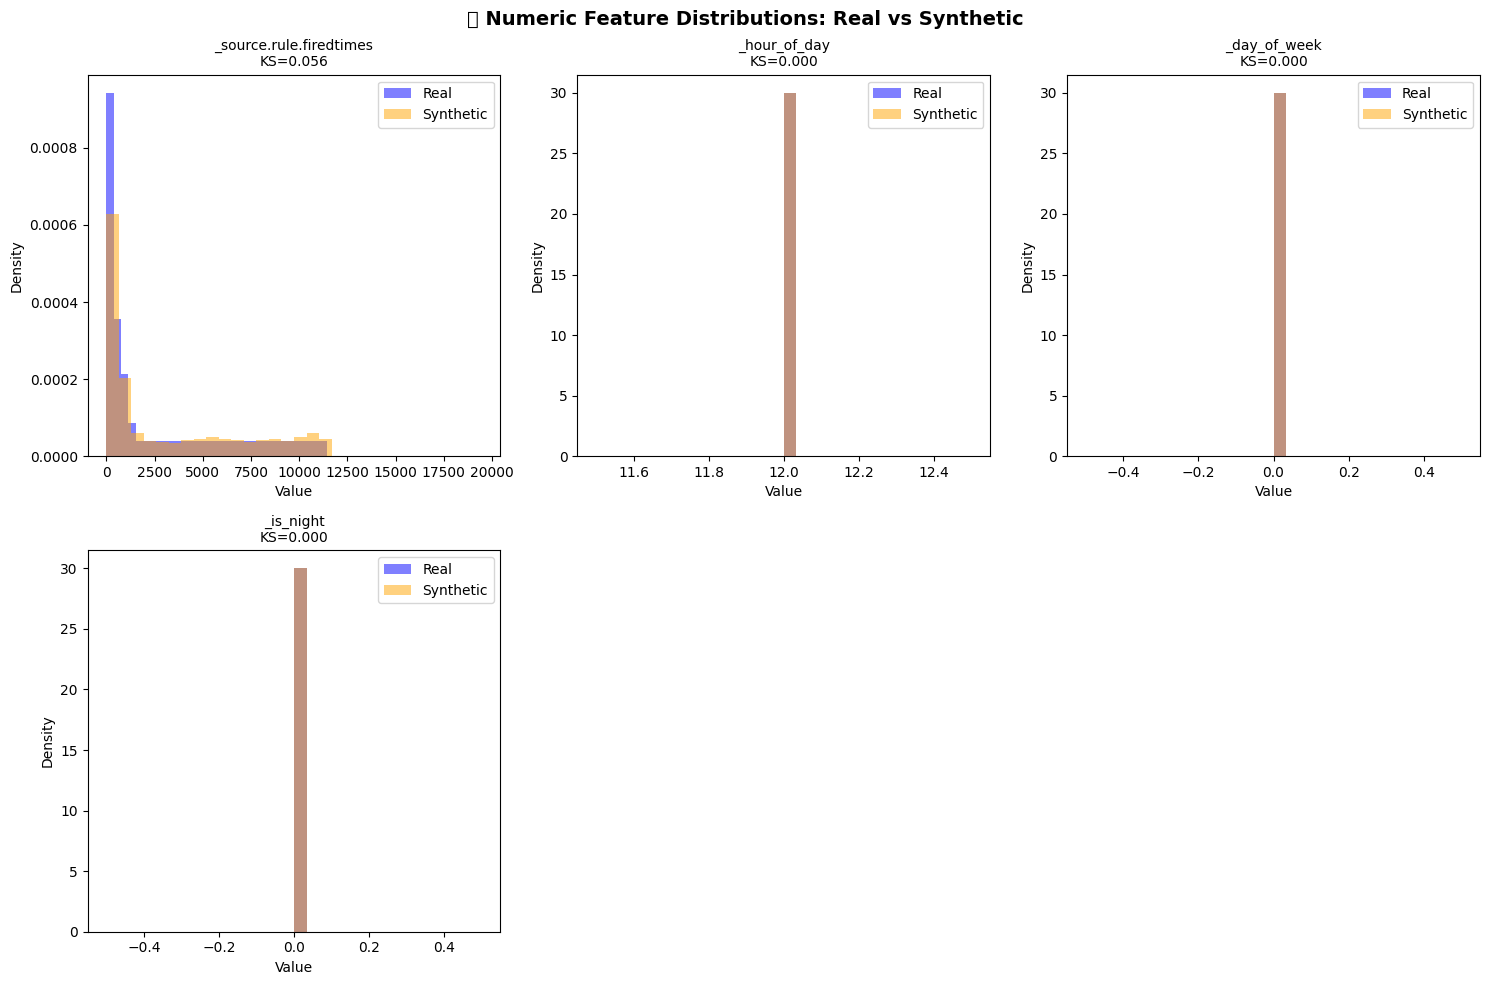

✅ Saved: /kaggle/working/realtabformer_output/numeric_distributions.png


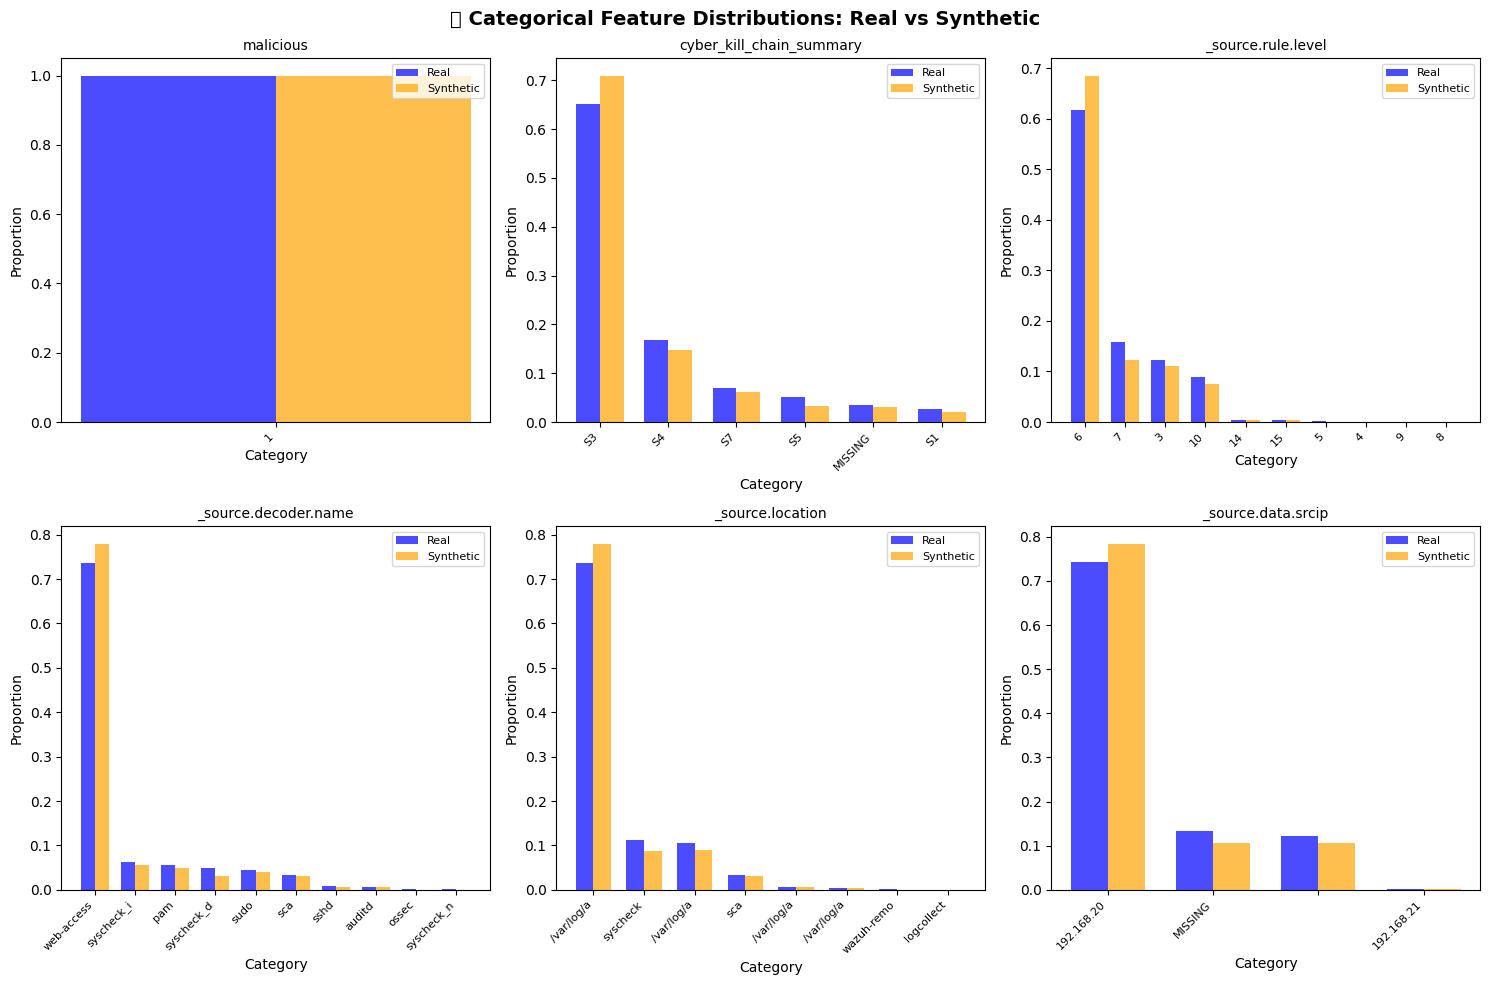

✅ Saved: /kaggle/working/realtabformer_output/categorical_distributions.png


In [23]:
# ============================================================================
# 📈 DISTRIBUTION VISUALIZATIONS
# ============================================================================

print("=" * 70)
print("📈 GENERATING DISTRIBUTION VISUALIZATIONS")
print("=" * 70)

# 1. Numeric Feature Distributions
if numeric_columns:
    n_numeric = min(len(numeric_columns), 6)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for idx, col in enumerate(numeric_columns[:n_numeric]):
        ax = axes[idx]
        
        # Real data
        real_vals = df[col].dropna()
        synth_vals = synthetic_samples[col].dropna()
        
        ax.hist(real_vals, bins=30, alpha=0.5, label='Real', color='blue', density=True)
        ax.hist(synth_vals, bins=30, alpha=0.5, label='Synthetic', color='orange', density=True)
        
        # Add KS statistic
        ks_stat, _ = ks_2samp(real_vals, synth_vals)
        ax.set_title(f'{col[:30]}\nKS={ks_stat:.3f}', fontsize=10)
        ax.legend()
        ax.set_xlabel('Value')
        ax.set_ylabel('Density')
    
    # Hide unused subplots
    for idx in range(n_numeric, 6):
        axes[idx].set_visible(False)
    
    plt.suptitle('📊 Numeric Feature Distributions: Real vs Synthetic', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/numeric_distributions.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {CONFIG['output_dir']}/numeric_distributions.png")

# 2. Categorical Feature Distributions
if categorical_columns:
    n_cat = min(len(categorical_columns), 6)
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for idx, col in enumerate(categorical_columns[:n_cat]):
        ax = axes[idx]
        
        # Get top categories
        real_counts = df[col].value_counts().head(10)
        synth_counts = synthetic_samples[col].value_counts()
        
        # Align
        categories = real_counts.index.tolist()
        real_vals = [real_counts.get(c, 0) / len(df) for c in categories]
        synth_vals = [synth_counts.get(c, 0) / len(synthetic_samples) for c in categories]
        
        x = np.arange(len(categories))
        width = 0.35
        
        ax.bar(x - width/2, real_vals, width, label='Real', color='blue', alpha=0.7)
        ax.bar(x + width/2, synth_vals, width, label='Synthetic', color='orange', alpha=0.7)
        
        ax.set_xlabel('Category')
        ax.set_ylabel('Proportion')
        ax.set_title(f'{col[:25]}', fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels([str(c)[:10] for c in categories], rotation=45, ha='right', fontsize=8)
        ax.legend(fontsize=8)
    
    # Hide unused subplots
    for idx in range(n_cat, 6):
        axes[idx].set_visible(False)
    
    plt.suptitle('📊 Categorical Feature Distributions: Real vs Synthetic', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/categorical_distributions.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {CONFIG['output_dir']}/categorical_distributions.png")

print("=" * 70)

🗺️ t-SNE EMBEDDING VISUALIZATION
   • PCA: 44 features → 44 components
   • Variance retained: 100.0%
   • Running t-SNE on 4,000 samples...


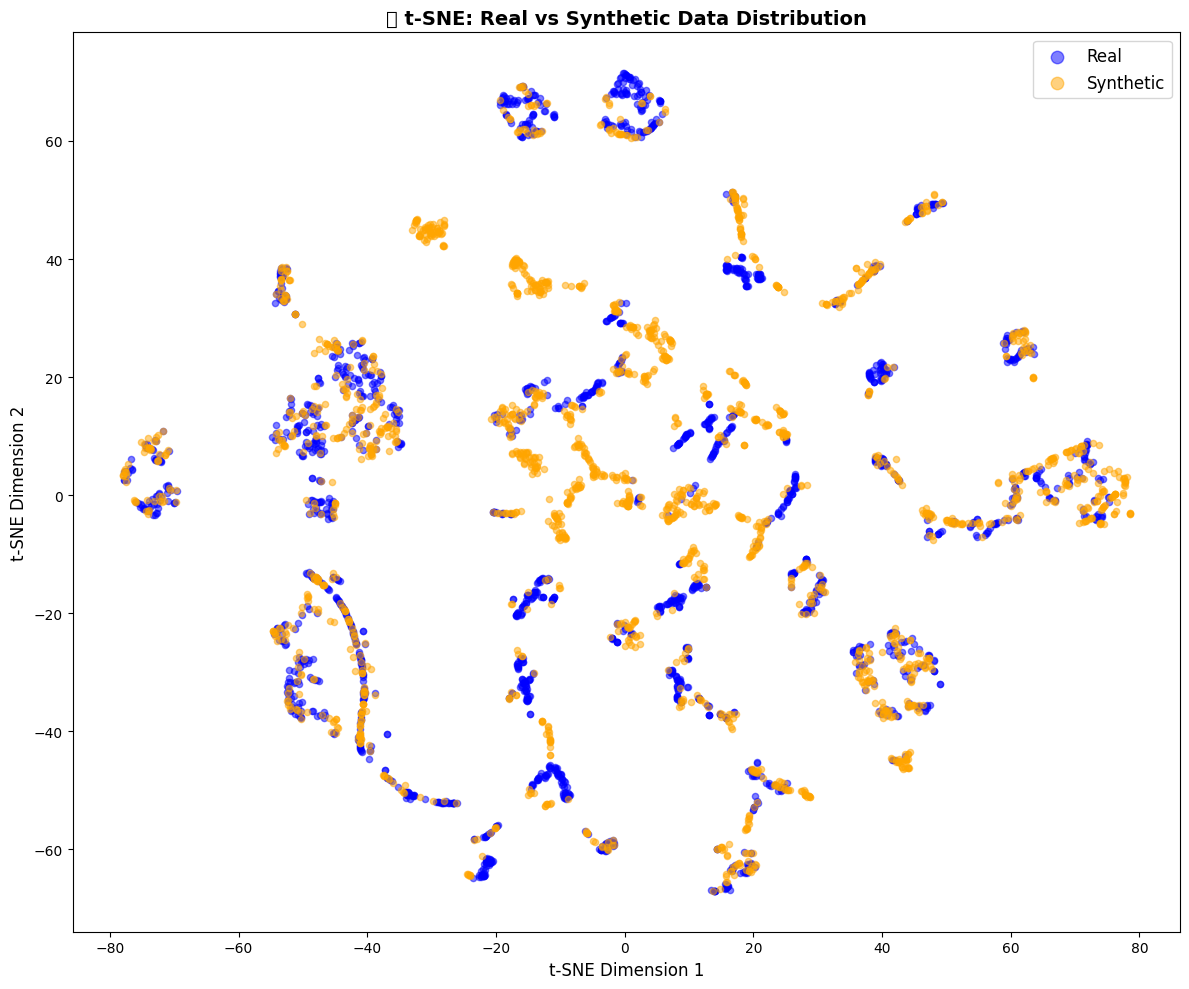


✅ Saved: /kaggle/working/realtabformer_output/tsne_visualization.png


In [24]:
# ============================================================================
# 🗺️ t-SNE VISUALIZATION
# ============================================================================

print("=" * 70)
print("🗺️ t-SNE EMBEDDING VISUALIZATION")
print("=" * 70)

def create_tsne_visualization(real_df, synth_df, cat_cols, n_samples=2000):
    """Create t-SNE visualization comparing real vs synthetic data"""
    
    # Sample data for faster computation
    real_sample = real_df.sample(min(n_samples, len(real_df)), random_state=CONFIG['random_seed'])
    synth_sample = synth_df.sample(min(n_samples, len(synth_df)), random_state=CONFIG['random_seed'])
    
    # Encode categorical columns
    combined = pd.concat([real_sample, synth_sample], ignore_index=True)
    feature_matrix = []
    
    for col in combined.columns:
        if col in cat_cols or combined[col].dtype == 'object':
            le = LabelEncoder()
            encoded = le.fit_transform(combined[col].astype(str))
            feature_matrix.append(encoded)
        elif combined[col].dtype in [np.float64, np.int64]:
            values = combined[col].fillna(0).values
            # Standardize
            if values.std() > 0:
                values = (values - values.mean()) / values.std()
            feature_matrix.append(values)
    
    if not feature_matrix:
        print("⚠️ No features available for t-SNE")
        return None
    
    X = np.column_stack(feature_matrix)
    
    # Apply PCA first for dimensionality reduction
    n_components = min(50, X.shape[1])
    pca = PCA(n_components=n_components, random_state=CONFIG['random_seed'])
    X_pca = pca.fit_transform(X)
    
    print(f"   • PCA: {X.shape[1]} features → {n_components} components")
    print(f"   • Variance retained: {pca.explained_variance_ratio_.sum():.1%}")
    
    # Apply t-SNE
    print(f"   • Running t-SNE on {len(combined):,} samples...")
    tsne = TSNE(n_components=2, random_state=CONFIG['random_seed'], perplexity=30, n_iter=1000)
    X_tsne = tsne.fit_transform(X_pca)
    
    # Create labels
    labels = ['Real'] * len(real_sample) + ['Synthetic'] * len(synth_sample)
    
    return X_tsne, labels, len(real_sample)

# Generate t-SNE
tsne_result = create_tsne_visualization(df, synthetic_samples, categorical_columns)

if tsne_result:
    X_tsne, labels, n_real = tsne_result
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot real data
    ax.scatter(X_tsne[:n_real, 0], X_tsne[:n_real, 1], 
               c='blue', alpha=0.5, label='Real', s=20)
    
    # Plot synthetic data
    ax.scatter(X_tsne[n_real:, 0], X_tsne[n_real:, 1], 
               c='orange', alpha=0.5, label='Synthetic', s=20)
    
    ax.set_xlabel('t-SNE Dimension 1', fontsize=12)
    ax.set_ylabel('t-SNE Dimension 2', fontsize=12)
    ax.set_title('🗺️ t-SNE: Real vs Synthetic Data Distribution', fontsize=14, fontweight='bold')
    ax.legend(fontsize=12, markerscale=2)
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/tsne_visualization.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\n✅ Saved: {CONFIG['output_dir']}/tsne_visualization.png")

print("=" * 70)

In [25]:
# ============================================================================
# 📊 INTERACTIVE PLOTLY VISUALIZATIONS
# ============================================================================

print("=" * 70)
print("📊 INTERACTIVE VISUALIZATIONS")
print("=" * 70)

# 1. Quality Scores Summary
quality_data = []
for r in quality_results['numeric']:
    quality_data.append({
        'Column': r['column'][:30],
        'Type': 'Numeric',
        'Score': 1 - r['ks_stat'],  # Convert to "quality score"
        'Metric': f"KS={r['ks_stat']:.3f}"
    })
for r in quality_results['categorical']:
    quality_data.append({
        'Column': r['column'][:30],
        'Type': 'Categorical',
        'Score': 1 - r['l1_dist'],
        'Metric': f"L1={r['l1_dist']:.3f}"
    })

quality_df = pd.DataFrame(quality_data)

if len(quality_df) > 0:
    fig = px.bar(
        quality_df.sort_values('Score', ascending=True).tail(20),
        x='Score',
        y='Column',
        color='Type',
        orientation='h',
        title='📊 Top 20 Features by Quality Score (Higher = Better)',
        color_discrete_map={'Numeric': '#3498db', 'Categorical': '#e74c3c'},
        hover_data=['Metric']
    )
    fig.add_vline(x=0.7, line_dash="dash", line_color="green", annotation_text="Good threshold")
    fig.update_layout(height=600, xaxis_range=[0, 1])
    fig.show()
    fig.write_html(f"{CONFIG['output_dir']}/quality_scores.html")
    print(f"✅ Saved: {CONFIG['output_dir']}/quality_scores.html")

# 2. Coverage Analysis for Categorical
if quality_results['categorical']:
    coverage_data = [{'Column': r['column'][:30], 'Coverage': r['coverage']} 
                     for r in quality_results['categorical']]
    coverage_df = pd.DataFrame(coverage_data)
    
    fig = px.bar(
        coverage_df.sort_values('Coverage', ascending=True),
        x='Coverage',
        y='Column',
        orientation='h',
        title='📊 Category Coverage: Synthetic vs Real',
        color='Coverage',
        color_continuous_scale='RdYlGn'
    )
    fig.add_vline(x=80, line_dash="dash", line_color="green", annotation_text="80% threshold")
    fig.update_layout(height=600, xaxis_range=[0, 100])
    fig.show()
    fig.write_html(f"{CONFIG['output_dir']}/coverage_analysis.html")
    print(f"✅ Saved: {CONFIG['output_dir']}/coverage_analysis.html")

print("=" * 70)

📊 INTERACTIVE VISUALIZATIONS


✅ Saved: /kaggle/working/realtabformer_output/quality_scores.html


✅ Saved: /kaggle/working/realtabformer_output/coverage_analysis.html


## 💾 Section 8: Save Results & Export

In [27]:
# ============================================================================
# 💾 SAVE ALL OUTPUTS
# ============================================================================

print("=" * 70)
print("💾 SAVING ALL OUTPUTS")
print("=" * 70)

# 1. Save synthetic data
synthetic_path = f"{CONFIG['output_dir']}/synthetic_apt_data.xlsx"
synthetic_samples.to_excel(synthetic_path, index=False)
print(f"✅ Synthetic data: {synthetic_path}")
print(f"   • Shape: {synthetic_samples.shape}")
print(f"   • Size: {os.path.getsize(synthetic_path) / 1e6:.2f} MB")

# 2. Save quality report
quality_report = pd.DataFrame(
    quality_results['numeric'] + quality_results['categorical']
)
quality_report_path = f"{CONFIG['output_dir']}/quality_report.xlsx"
quality_report.to_excel(quality_report_path, index=False)
print(f"✅ Quality report: {quality_report_path}")

# 3. Save combined dataset (real + synthetic)
combined_data = pd.concat([
    df.assign(data_source='real'),
    synthetic_samples.assign(data_source='synthetic')
], ignore_index=True)
combined_path = f"{CONFIG['output_dir']}/combined_apt_data.xlsx"
combined_data.to_excel(combined_path, index=False)
print(f"✅ Combined data: {combined_path}")
print(f"   • Shape: {combined_data.shape}")

# 4. Save summary report
summary_report = {
    'timestamp': datetime.now().isoformat(),
    'pipeline_version': '2.0-SecBERT',
    'original_data': {
        'path': CONFIG['data_path'],
        'shape': list(raw_data.shape),
        'columns': len(raw_data.columns)
    },
    'feature_selection': {
        'total_features_requested': len(REALTABFORMER_COLUMNS),
        'features_found': len(existing_columns),
        'features_missing': len(missing_columns),
        'missing_list': missing_columns
    },
    'preprocessed_data': {
        'shape': list(df.shape),
        'text_columns': text_columns,
        'categorical_columns': categorical_columns,
        'numeric_columns': numeric_columns,
        'boolean_columns': boolean_columns
    },
    'secbert_embeddings': {
        'enabled': CONFIG['use_secbert'],
        'model': CONFIG['secbert_model'],
        'columns_embedded': list(text_embeddings.keys()),
        'embedding_dim': CONFIG['embedding_dim']
    },
    'synthetic_data': {
        'shape': list(synthetic_samples.shape),
        'ratio': CONFIG['synthetic_ratio']
    },
    'quality_metrics': {
        'avg_ks_stat': quality_results['summary']['avg_ks'],
        'avg_l1_dist': quality_results['summary']['avg_l1'],
        'avg_coverage': quality_results['summary']['avg_coverage'],
        'acceptable_percentage': acceptable_pct
    },
    'ml_utility': ml_results if ml_results else {},
    'training': {
        'epochs': CONFIG['epochs'],
        'batch_size': CONFIG['batch_size'],
        'duration_minutes': train_duration
    }
}

summary_path = f"{CONFIG['output_dir']}/summary_report.json"
with open(summary_path, 'w') as f:
    json.dump(summary_report, f, indent=2, default=str)
print(f"✅ Summary report: {summary_path}")

# 5. Save column mappings with detailed info
column_info = {
    'selected_columns': selected_columns,
    'column_categories': {
        'text': text_columns,
        'categorical': categorical_columns,
        'numeric': numeric_columns,
        'boolean': boolean_columns
    },
    'secbert_embedded_columns': list(text_embeddings.keys()),
    'feature_groups': {
        'target': ['malicious', 'cyber_kill_chain_summary'],
        'top_features': [c for c in selected_columns if c in [
            '_source.rule.level', '_source.rule.firedtimes', '_source.decoder.name',
            '_source.location', '_source.data.srcip'
        ]],
        'mitre': [c for c in selected_columns if 'mitre' in c.lower()],
        'audit': [c for c in selected_columns if 'audit' in c],
        'syscheck': [c for c in selected_columns if 'syscheck' in c],
        'sca': [c for c in selected_columns if 'sca' in c.lower()],
        'network': [c for c in selected_columns if any(x in c for x in ['protocol', 'srcport', 'url'])],
        'flags': [c for c in selected_columns if c.startswith('has_')]
    }
}
columns_path = f"{CONFIG['output_dir']}/column_mappings.json"
with open(columns_path, 'w') as f:
    json.dump(column_info, f, indent=2)
print(f"✅ Column mappings: {columns_path}")

print("\n" + "=" * 70)
print(f"📁 ALL OUTPUTS SAVED TO: {CONFIG['output_dir']}/")
print("=" * 70)

💾 SAVING ALL OUTPUTS
✅ Synthetic data: /kaggle/working/realtabformer_output/synthetic_apt_data.xlsx
   • Shape: (50836, 44)
   • Size: 10.50 MB
✅ Quality report: /kaggle/working/realtabformer_output/quality_report.xlsx
✅ Combined data: /kaggle/working/realtabformer_output/combined_apt_data.xlsx
   • Shape: (76254, 45)
✅ Summary report: /kaggle/working/realtabformer_output/summary_report.json
✅ Column mappings: /kaggle/working/realtabformer_output/column_mappings.json

📁 ALL OUTPUTS SAVED TO: /kaggle/working/realtabformer_output/


In [28]:
# ============================================================================
# 📋 FINAL SUMMARY
# ============================================================================

print("=" * 70)
print("🏁 REaLTabFormer + SecBERT PIPELINE COMPLETE")
print("=" * 70)

print(f"""
📊 DATA SUMMARY:
   ┌─────────────────────────────────────────────────────────────┐
   │  Original Data:      {raw_data.shape[0]:>8,} rows × {raw_data.shape[1]:>3} columns     │
   │  Preprocessed Data:  {df.shape[0]:>8,} rows × {df.shape[1]:>3} columns     │
   │  Synthetic Data:     {synthetic_samples.shape[0]:>8,} rows × {synthetic_samples.shape[1]:>3} columns     │
   │  Combined Data:      {combined_data.shape[0]:>8,} rows × {combined_data.shape[1]:>3} columns     │
   └─────────────────────────────────────────────────────────────┘

📋 FEATURE BREAKDOWN:
   ┌─────────────────────────────────────────────────────────────┐
   │  Text columns:          {len(text_columns):>3} (🔐 {len(text_embeddings)} with SecBERT)        │
   │  Categorical columns:   {len(categorical_columns):>3}                              │
   │  Numeric columns:       {len(numeric_columns):>3}                              │
   │  Boolean columns:       {len(boolean_columns):>3}                              │
   └─────────────────────────────────────────────────────────────┘

📈 QUALITY METRICS:
   ┌─────────────────────────────────────────────────────────────┐
   │  Average KS Statistic:    {quality_results['summary']['avg_ks']:>6.4f} (lower is better)   │
   │  Average L1 Distance:     {quality_results['summary']['avg_l1']:>6.4f} (lower is better)   │
   │  Average Coverage:        {quality_results['summary']['avg_coverage']:>6.1f}%                       │
   │  Acceptable Features:     {acceptable_pct:>6.1f}%                       │
   └─────────────────────────────────────────────────────────────┘

🔐 SecBERT EMBEDDINGS:
   ┌─────────────────────────────────────────────────────────────┐
   │  Model: {CONFIG['secbert_model']:<48} │
   │  Embedding Dimension: {CONFIG['embedding_dim']:<35} │
   │  Columns Embedded: {len(text_embeddings):<38} │
   └─────────────────────────────────────────────────────────────┘

⏱️ TRAINING:
   ┌─────────────────────────────────────────────────────────────┐
   │  Epochs:                  {CONFIG['epochs']:>6}                          │
   │  Training Time:           {train_duration:>6.1f} minutes               │
   │  Generation Time:         {gen_duration:>6.1f} minutes               │
   └─────────────────────────────────────────────────────────────┘
""")

if ml_results:
    print(f"""🧪 ML UTILITY:
   ┌─────────────────────────────────────────────────────────────┐
   │  TSTR Accuracy:           {ml_results['tstr_accuracy']:>6.1%}                       │
   │  TRTR Accuracy:           {ml_results['trtr_accuracy']:>6.1%}                       │
   │  Utility Ratio:           {ml_results['utility_ratio']:>6.1%}                       │
   └─────────────────────────────────────────────────────────────┘
""")

print(f"""📁 OUTPUT FILES:
   • {CONFIG['output_dir']}/synthetic_apt_data.xlsx
   • {CONFIG['output_dir']}/combined_apt_data.xlsx
   • {CONFIG['output_dir']}/quality_report.xlsx
   • {CONFIG['output_dir']}/summary_report.json
   • {CONFIG['output_dir']}/column_mappings.json
   • {CONFIG['output_dir']}/secbert_embeddings.pkl
   • {CONFIG['output_dir']}/realtabformer_model/

✅ VERDICT: {verdict}
""")

# Print feature list for reference
print("=" * 70)
print("📋 FEATURES USED (FOR REFERENCE):")
print("=" * 70)
for i, col in enumerate(selected_columns, 1):
    category = 'text' if col in text_columns else 'cat' if col in categorical_columns else 'num' if col in numeric_columns else 'bool'
    secbert = '🔐' if col in text_embeddings else ''
    print(f"   {i:2d}. {col:<50} [{category}] {secbert}")

print("=" * 70)
print("🎉 Pipeline completed successfully!")
print("=" * 70)

🏁 REaLTabFormer + SecBERT PIPELINE COMPLETE

📊 DATA SUMMARY:
   ┌─────────────────────────────────────────────────────────────┐
   │  Original Data:        25,418 rows ×  41 columns     │
   │  Preprocessed Data:    25,418 rows ×  44 columns     │
   │  Synthetic Data:       50,836 rows ×  44 columns     │
   │  Combined Data:        76,254 rows ×  45 columns     │
   └─────────────────────────────────────────────────────────────┘

📋 FEATURE BREAKDOWN:
   ┌─────────────────────────────────────────────────────────────┐
   │  Text columns:           12 (🔐 6 with SecBERT)        │
   │  Categorical columns:    24                              │
   │  Numeric columns:         4                              │
   │  Boolean columns:         4                              │
   └─────────────────────────────────────────────────────────────┘

📈 QUALITY METRICS:
   ┌─────────────────────────────────────────────────────────────┐
   │  Average KS Statistic:    0.0141 (lower is better)   │
   │  Ave

## 🔄 Section 9: Load Pre-trained Model (Optional)

Use this section to load a previously trained model and generate more synthetic data.

In [ ]:
# ============================================================================
# 🔄 LOAD PRE-TRAINED MODEL (OPTIONAL)
# ============================================================================
# Uncomment this cell to load a previously trained model

"""
# Load saved model
model_path = "realtabformer_output/realtabformer_model"

if os.path.exists(model_path):
    print(f"Loading model from: {model_path}")
    loaded_model = REaLTabFormer.load_from_dir(model_path)
    
    # Generate new samples
    new_synthetic = loaded_model.sample(n_samples=10000)
    print(f"Generated {len(new_synthetic)} new samples")
    print(new_synthetic.head())
else:
    print(f"Model not found at: {model_path}")
"""

print("💡 Uncomment this cell to load a pre-trained model")

## 📚 Appendix: Pipeline Architecture & Feature Summary

### 🔧 Pipeline Architecture

```
┌─────────────────────────────────────────────────────────────────────┐
│                   REaLTabFormer + SecBERT Pipeline                   │
├─────────────────────────────────────────────────────────────────────┤
│                                                                      │
│  ┌──────────────┐    ┌──────────────┐    ┌──────────────────────┐  │
│  │  Raw Data    │───▶│  Feature     │───▶│  Preprocessing       │  │
│  │  (Wazuh)     │    │  Selection   │    │  + Boolean Flags     │  │
│  └──────────────┘    └──────────────┘    └──────────────────────┘  │
│                                                   │                  │
│                                                   ▼                  │
│  ┌──────────────┐    ┌──────────────┐    ┌──────────────────────┐  │
│  │  SecBERT     │◀───│  Text        │◀───│  Column Type         │  │
│  │  Embeddings  │    │  Columns     │    │  Detection           │  │
│  └──────────────┘    └──────────────┘    └──────────────────────┘  │
│         │                                                           │
│         ▼                                                           │
│  ┌──────────────────────────────────────────────────────────────┐  │
│  │                    REaLTabFormer (GPT-2)                       │  │
│  │  • Tokenizes tabular data as text sequences                   │  │
│  │  • Learns column relationships via attention                   │  │
│  │  • Generates synthetic rows autoregressively                   │  │
│  └──────────────────────────────────────────────────────────────┘  │
│         │                                                           │
│         ▼                                                           │
│  ┌──────────────┐    ┌──────────────┐    ┌──────────────────────┐  │
│  │  Synthetic   │───▶│  Quality     │───▶│  Combined Dataset    │  │
│  │  Data        │    │  Validation  │    │  (Real + Synthetic)  │  │
│  └──────────────┘    └──────────────┘    └──────────────────────┘  │
│                                                                      │
└─────────────────────────────────────────────────────────────────────┘
```

### 📋 Complete Feature List (37 Features)

| Category | Feature | Type | SecBERT |
|----------|---------|------|---------|
| **Target** | `malicious` | categorical | ❌ |
| **Target** | `cyber_kill_chain_summary` | categorical | ❌ |
| **Top Features** | `_source.rule.level` | numeric | ❌ |
| **Top Features** | `_source.rule.firedtimes` | numeric | ❌ |
| **Top Features** | `_source.decoder.name` | categorical | ❌ |
| **Top Features** | `_source.location` | categorical | ❌ |
| **Top Features** | `_source.@timestamp` | text | ❌ |
| **Top Features** | `_source.data.srcip` | categorical | ❌ |
| **Top Features** | `_source.syscheck.md5_after` | text | ❌ |
| **Top Features** | `_source.syscheck.sha256_after` | text | ❌ |
| **Textual** | `_source.rule.description` | text | ✅ |
| **Textual** | `_source.data.command` | text | ✅ |
| **MITRE** | `_source.rule.mitre.tactic` | categorical | ❌ |
| **MITRE** | `_source.rule.mitre.id` | categorical | ❌ |
| **MITRE** | `_source.rule.groups` | categorical | ❌ |
| **Audit** | `_source.data.audit.syscall` | categorical | ❌ |
| **Audit** | `_source.data.audit.exe` | text | ✅ |
| **Audit** | `_source.data.audit.command` | text | ✅ |
| **Audit** | `_source.data.audit.uid` | numeric | ❌ |
| **Audit** | `_source.data.audit.euid` | numeric | ❌ |
| **Audit** | `_source.data.audit.gid` | numeric | ❌ |
| **Audit** | `_source.data.audit.auid` | numeric | ❌ |
| **Audit** | `_source.data.audit.success` | categorical | ❌ |
| **Syscheck** | `_source.syscheck.event` | categorical | ❌ |
| **Syscheck** | `_source.syscheck.path` | text | ✅ |
| **Syscheck** | `_source.syscheck.perm_before` | categorical | ❌ |
| **Syscheck** | `_source.syscheck.perm_after` | categorical | ❌ |
| **Syscheck** | `_source.syscheck.size_before` | numeric | ❌ |
| **Syscheck** | `_source.syscheck.size_after` | numeric | ❌ |
| **Syscheck** | `_source.syscheck.changed_attributes` | categorical | ❌ |
| **SCA** | `_source.data.sca.check.result` | categorical | ❌ |
| **SCA** | `_source.data.sca.failed` | numeric | ❌ |
| **SCA** | `_source.data.sca.passed` | numeric | ❌ |
| **SCA** | `_source.data.sca.score` | numeric | ❌ |
| **Network** | `_source.data.protocol` | categorical | ❌ |
| **Network** | `_source.data.srcport` | numeric | ❌ |
| **Network** | `_source.data.url` | text | ✅ |
| **Flags** | `has_audit` | boolean | ❌ |
| **Flags** | `has_syscheck` | boolean | ❌ |
| **Flags** | `has_sca` | boolean | ❌ |
| **Flags** | `has_network` | boolean | ❌ |

### 🔐 SecBERT Embedded Columns (6)
1. `_source.rule.description` - Rule text descriptions
2. `_source.data.command` - Shell commands
3. `_source.data.audit.exe` - Executable paths
4. `_source.data.audit.command` - Audit commands
5. `_source.syscheck.path` - File paths
6. `_source.data.url` - URLs

### Tips for Best Results:

1. **Increase epochs** if quality is low (try 200-300)
2. **Monitor GPU memory** when using SecBERT with large datasets
3. **Use gradient accumulation** for larger effective batch size
4. **Check coverage metrics** for categorical columns
5. **Validate MITRE mappings** in synthetic data for security relevance